# Wrangling and Stats Models Review

First, packages. Statsmodels is the primary statistical anlaysis package in python, as is numpy for numeric operations. Pandas is the primary for data wrangling. 

There are two calls primarily for statsmodels ... the api and the formulas api

In [1]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

Statistical tests will be in scientific python SciPy. This one is different. We want to import the stats library

In [2]:
from scipy import stats

Numpy and pandas

In [3]:
import numpy as np
import pandas as pd

get data

In [4]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

titanic = pd.read_csv(url)
titanic_raw = titanic.copy()

## Section 1 - Inspect and explore

1. Inspect and explore
- [ ] Get the number of rows and columns.
- [ ] Inspect the data
- [ ] Display the first 10 rows.
- [ ] Display the last 5 rows.
- [ ] List all column names.
- [ ] Identify the data type of every column.
- [ ] Generate descriptive statistics for numeric variables.
- [ ] Generate descriptive statistics for categorical variables.
- [ ] Count unique values in every column.
- [ ] Get frequency counts for class, sex, and embarked.
- [ ] Calculate the percentage of missing values in every column, sorted descending.

Get the number of rows and columns.

There are a few ways to do this. First, `.shape` returns both. Second, you can also use `len(df)`.

In [5]:
titanic.shape

(891, 15)

In [6]:
len(titanic)

891

In [7]:
len(titanic.columns)

15

Inspect the data

There are a few ways we should always inspect the data. First `.info()` gives us information on every column. `.describe()` also gives us detailed stats on every numeric column. 

In [8]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


> Right away, we see there are some columns with a few nulls! `deck` is a real problem for us. We also have weak `age` information. There also does not appear to be any person key.

In [9]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


> That's a little hard to read, but we can round the df with `.round()`

In [10]:
(
    titanic
    .describe()
    .round(2)
)

,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,714.00,891.00,891.00,891.00
mean,0.38,2.31,29.70,0.52,0.38,32.20
std,0.49,0.84,14.53,1.10,0.81,49.69
min,0.00,1.00,0.42,0.00,0.00,0.00
25%,0.00,2.00,20.12,0.00,0.00,7.91
50%,0.00,3.00,28.00,0.00,0.00,14.45
75%,1.00,3.00,38.00,1.00,0.00,31.00
max,1.00,3.00,80.00,8.00,6.00,512.33


> Much better. 

Display the first 10 rows.
Display the last 5 rows.

This is part of inspecting the dataset--look at the data!

In [11]:
(
    titanic
    .head(5)
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [12]:
(
    titanic
    .tail(10)
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
881,0,3,male,33.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
882,0,3,female,22.0,0,0,10.5167,S,Third,woman,False,NaN,Southampton,no,True
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True


> This uses row indexes to we are assured the correct number of rows displayed

> Note that we can also grab rows with `.iloc[]` (integer location) for the same results. This uses `:5`. We index from 0 and it is always `inclusive: exclusive`. So `:5` meaning rows 0, 1, 2, 3, 4 (i.e., the first 5). 

In [13]:
titanic.iloc[:5]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


You can start with `-10:` meaning 10 from the last, and go to the end.

In [14]:
titanic.iloc[-10:]

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
881,0,3,male,33.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
882,0,3,female,22.0,0,0,10.5167,S,Third,woman,False,NaN,Southampton,no,True
883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True


List all column names. Identify the data type of every column.

Let's look at columns with `.columns` and `.dtypes` in more detail. 

First, columns:

In [15]:
(
    titanic.columns
)

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

> What a funny object. What type is it? Check with `type()`

In [16]:
type(titanic.columns)

pandas.core.indexes.base.Index

> We see this is actually the index (column names) of the dataframe. We can do some work with these indexes if we want. First, let's convert this to a python list, for possible use later.

In [17]:
colnames = titanic.columns.to_list()
colnames

['survived',
 'pclass',
 'sex',
 'age',
 'sibsp',
 'parch',
 'fare',
 'embarked',
 'class',
 'who',
 'adult_male',
 'deck',
 'embark_town',
 'alive',
 'alone']

> Unlike in R, we cannot mutate the indexes by writing over them.

In [18]:
try:
    titanic.columns[4] = "overwrite"
except:
    print("can't do that")

can't do that


> However, we can give the axes names if we want with `.rename_axis(index=X, columns=X)`. Note that `index` is pandas-speak for rows, and `columns` is pandas speak for columns.

In [19]:
titanic = (
    titanic
    .rename_axis(
        index="personid", 
        columns="colnames"
        )
    )

titanic

colnames,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
personid,,,,,,,,,,,,,,,
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False


> Many operations will give axes names. Often, our bigger task is to drop those names by setting them to `None`.

In [20]:
titanic = (
    titanic
    .rename_axis(index=None, columns=None)
)

titanic

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


> We can also row index with `.reset_index(drop=True)` to reset the index back to 0, 1, 2, 3 etc. We will see later that many operations mess up the row indexes and we want to reset them. Right now, it doesn't do anything since that's already our index:


In [21]:
titanic.reset_index(drop=True)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


> Lastly, we can move the index into the dataframe and make it a column with `.reset_index()`. We can rename columns to give it a new name as well with `.rename(columns={dict})`. These kinds of dicts always follow the pattern `"old": "new"`.

In [22]:
titanic = (
    titanic
    .reset_index()
    .rename(columns={"index": "personid"})
    )

titanic

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


> We have now made some changes to the titanic dataset. We can confirm row counts are steady with an assert.

In [23]:
assert len(titanic) == len(titanic_raw)

> Next, let's inspect the data types with `.dtypes()`

In [24]:
(
    titanic.dtypes
)

personid         int64
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

> You will see that is a series. 

In [25]:
type(titanic.dtypes)

pandas.core.series.Series

> And just for fun, a series we can convert to a dataframe with `.to_frame("varname")`. Just for fun, we can see how we can make a table

In [26]:
(
    titanic.dtypes
    .to_frame("Data Type")
    .reset_index()
    .rename(columns={"index": "Column Name"})
)

,Column Name,Data Type
0,personid,int64
1,survived,int64
2,pclass,int64
3,sex,object
4,age,float64
5,sibsp,int64
6,parch,int64
7,fare,float64
8,embarked,object
9,class,object


Generate descriptive statistics for numeric variables. Generate descriptive statistics for categorical variables.

We can grab sets of columns with `.select_dtypes(include=["number", "object", "category"])`. We can select up to all of those 3 options. We can then run our own aggregations. 

We can create aggregations with `.agg()`. 

This method is a little weird: for cases when you run one ONE function for specific columns, you list aggregations and follow them with a tuple containing `name = ("column", "func")` where func is often `lambda d: d.mean()` (d in this case is the column in question).

However, for a dataframe, we can also give a list of functions:

In [27]:
(
    titanic
    .select_dtypes(include="number")
    .agg(
        ["mean", "std", "size", "sum"]
    )
    .round(2)
)

,personid,survived,pclass,age,sibsp,parch,fare
mean,445.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
size,891.00,891.00,891.00,891.00,891.00,891.00,891.00
sum,396495.00,342.00,2057.00,21205.17,466.00,340.00,28693.95


> The easier thing to do is use `.describe()` on the numeric data. Try transposing with `T`:

In [28]:
(
    titanic
    .select_dtypes(include="number")
    .describe()
    .round(2)
    .T
)

,count,mean,std,min,25%,50%,75%,max
personid,891.0,445.00,257.35,0.00,222.50,445.00,667.5,890.00
survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
sibsp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


Same for category/object (always use both). It gives different stats.

In [29]:
(
    titanic
    .select_dtypes(include=["object", "category"])
    .describe()
)

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


> Note that `.mode()` returns a list as you can have multiple modes. Usually consider `mode()[0]` or do a manual inspect.

In [30]:
(
    titanic
    .agg(
        mode_embarked = ("embarked", lambda d: d.mode()[0])
    )
)

,embarked
mode_embarked,S


Count unique values in every column.

`.nunique()` is a simple aggregate option

In [31]:
(
    titanic
    .agg(["nunique"])
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
nunique,891,2,3,2,88,7,7,248,3,3,3,2,7,3,2,2


Get frequency counts for class, sex, and embarked.

Use `.value_counts()`

In [32]:
(
    titanic["class"]
    .value_counts()
)

class
Third     491
First     216
Second    184
Name: count, dtype: int64

In [33]:
(
    titanic["sex"]
    .value_counts()
)

sex
male      577
female    314
Name: count, dtype: int64

In [34]:
(
    titanic["embarked"]
    .value_counts()
)

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

> You have optiosn to NOT drop missing values, and also to normalize (get percentages)

In [35]:
(
    titanic["deck"]
    .value_counts(
        dropna=False, 
        normalize=True
    )
)

deck
NaN    0.772166
C      0.066218
B      0.052750
D      0.037037
E      0.035915
A      0.016835
F      0.014590
G      0.004489
Name: proportion, dtype: float64

> We see here that 77% are missing!

> What if we wanted a table with counts AND proportions?

> The strategy here is to create a series of counts and a series of proportions. Start with one column, then `.assign()` another. This uses more advanced functions than we know now, but follow the logic.

In [36]:
(
    titanic
    .groupby("deck", observed=True, dropna=False)
    .agg(
        n = ("deck", "size")
    )
    .assign(
        #make a new series
        prop = titanic["deck"].value_counts(normalize=True, dropna= False),

        #or simply calculate total
        propalt = lambda d: d["n"]/len(titanic)
    )
)

,n,prop,propalt
deck,,,
A,15,0.016835,0.016835
B,47,0.052750,0.052750
C,59,0.066218,0.066218
D,33,0.037037,0.037037
E,32,0.035915,0.035915
F,13,0.014590,0.014590
G,4,0.004489,0.004489
NaN,688,0.772166,0.772166


> You could also do it where you start with a `.value_counts()` series and make it a frame with `to_frame()`, then do the `.assign()`.

In [37]:
(
    titanic["deck"]
    .value_counts(dropna=True)
    .to_frame("n")
    .assign(
        prop = titanic["deck"].value_counts(dropna=True, normalize=True).round(2)
    )
    .reset_index()
    .sort_values("deck")
)

,deck,n,prop
4,A,15,0.07
1,B,47,0.23
0,C,59,0.29
2,D,33,0.16
3,E,32,0.16
5,F,13,0.06
6,G,4,0.02


Calculate the percentage of missing values in every column, sorted descending.

We will use `.isna()` to get the missigness, and then we can use `.agg()` to run counts, and means. We can clean it up by `.rename` and use `.assign` to cast and round. We can sort and select in the order we want also

In [38]:
(
    titanic
    .isna()
    .agg(["mean", "sum"])
    .T
    .assign(
        mean = lambda d: d["mean"].round(2),
        sum = lambda d: d["sum"].astype("int64")
    )
    .rename(columns={"mean": "prop", "sum": "missing"})
    .sort_values("missing", ascending=False)
    [["missing", "prop"]]


)

,missing,prop
deck,688,0.77
age,177,0.20
embarked,2,0.00
embark_town,2,0.00
personid,0,0.00
survived,0,0.00
pclass,0,0.00
sex,0,0.00
sibsp,0,0.00
parch,0,0.00


Bonus goal -- can we get the glimpse we got in R?

Yes, but it requires a `.merge()` and transpose with `.T`

In [39]:
(
    titanic
    .agg(
        ["dtypes", "count", "nunique"]
    )
    .T
    .reset_index()
    .merge(
        titanic.head(5).T.reset_index(),
        on="index",
        how="left",
        validate="one_to_one"
    )
)

,index,dtypes,count,nunique,0,1,2,3,4
0,personid,int64,891,891,0,1,2,3,4
1,survived,int64,891,2,0,1,1,1,0
2,pclass,int64,891,3,3,1,3,1,3
3,sex,object,891,2,male,female,female,female,male
4,age,float64,714,88,22.0,38.0,26.0,35.0,35.0
5,sibsp,int64,891,7,1,1,0,1,0
6,parch,int64,891,7,0,0,0,0,0
7,fare,float64,891,248,7.25,71.2833,7.925,53.1,8.05
8,embarked,object,889,3,S,C,S,S,S
9,class,object,891,3,Third,First,Third,First,Third


## Section 2 - Cleaning

2. Clean the data
- [ ] Count fully duplicated rows.
- [ ] Identify which rows are duplicated.
- [ ] Remove duplicates from a working copy.
- [ ] Check for missing values in age, fare, and embarked.
- [ ] Replace missing age values with the median age.
- [ ] Replace missing embarked values with the most frequent category.
- [ ] Convert class to an ordered categorical variable.
- [ ] Rename sibsp and parch to more descriptive column names.
- [ ] Verify the number of rows before and after cleaning.

Count fully duplicated rows.

Use `.duplicated()` to select duplicated rows, then count them. Or, we could diff `titanic.drop_duplicates()` and `len(titanic)`

In [40]:
titanic.duplicated().sum(0)

np.int64(0)

No duplicates! Right, because we made a personid column. Subset that out with `.columns(drop=[])` and `.duplicated(subset=...)`

For this, we are doing a new method on an index, and that is `.drop()`

In [41]:
(
    titanic
    .duplicated(
        subset=titanic.columns.drop("personid")
    )
    .sum()
)

np.int64(107)

In [42]:
# also just drop the column first
(
    titanic
    .drop(columns=["personid"])
    .duplicated()
    .sum()
)

np.int64(107)

Identify which rows are duplicated.

In [43]:
(
    titanic
    .loc[
        lambda d: d.drop(columns="personid").duplicated()
    ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
47,47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
76,76,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
77,77,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
87,87,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
95,95,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
870,870,0,3,male,26.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
877,877,0,3,male,19.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
878,878,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
884,884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True


> Can flag which rows are NOT duplicated

In [44]:
(
    titanic
    .loc[
        lambda d: ~d.drop(columns="personid").duplicated()
    ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


Remove duplicates from a working copy.

Key is `.drop_duplicates()`

In [45]:
(
    titanic
    .drop(columns="personid")
    .drop_duplicates()
    
)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


> We can also drop rows that duplicate patterns on sex and embarked:


In [46]:
(
    titanic
    .drop_duplicates(subset=["sex", "embarked"])
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
5,5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
22,22,1,3,female,15.0,0,0,8.0292,Q,Third,child,False,NaN,Queenstown,yes,True
26,26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
61,61,1,1,female,38.0,0,0,80.0000,NaN,First,woman,False,B,NaN,yes,True


Check for missing values in age, fare, and embarked.

In [47]:
titanic["age"].isna().sum()

np.int64(177)

In [48]:
titanic["fare"].isna().sum()

np.int64(0)

In [49]:
titanic["embarked"].isna().sum()

np.int64(2)

Replace missing age values with the median age.

`.fillna()` is our friend. We can provide 
- a scalar to always swap in
- a series with corresponding indexes to swap in when needed.

Try scalar version

In [50]:
median_age = titanic["age"].median()
(
    titanic
    .assign(
        age_impute = lambda d: d["age"].fillna(median_age) 
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_impute
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,22.0
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,38.0
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,26.0
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,35.0
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,27.0
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,19.0
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,28.0
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,26.0


> Try series version. Replace missing values with median age for the given sex and class. To do this, we will use the pattern:

`df.groupby()["col"].transform()`

This is a rare case where we do `.groupby("group")["col"]`

In [51]:
impute_series = titanic.groupby(["sex", "class"])["age"].transform("median")

#verify i didn't screw up
assert len(impute_series) == len(titanic)

df = (
    titanic
    .assign(
        age = lambda d: d["age"].fillna(impute_series)
    )
)

display(df)

# validate it worked
print(f"You had {df["age"].isna().sum()} missing values")

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,888,0,3,female,21.5,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


You had 0 missing values


Replace missing embarked values with the most frequent category.

Use `.mode[0]`

In [52]:
embarked_mode = titanic["embarked"].mode()[0]
print(embarked_mode + " is the mode")
df = (
    titanic
    .assign(
        embarked_impute = lambda d: d["embarked"].fillna(embarked_mode)
    )
)

display(df)

print(f"You have {df["embarked_impute"].isna().sum()} missing values now")


S is the mode


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,embarked_impute
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,S
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,C
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,S
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,S
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,S
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,S
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,S
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,C


You have 0 missing values now


Convert class to an ordered categorical variable.

In [53]:
titanic["class"] = pd.Categorical(
    titanic["class"],
    categories=["Third", "Second", "First"],
    ordered=True
)

> now use for sorts

In [54]:
titanic.sort_values(["class", "age"], ascending=[False, True])

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
305,305,1,1,male,0.92,1,2,151.5500,S,First,child,False,C,Southampton,yes,False
297,297,0,1,female,2.00,1,2,151.5500,S,First,child,False,C,Southampton,no,False
445,445,1,1,male,4.00,0,2,81.8583,S,First,child,False,A,Southampton,yes,False
802,802,1,1,male,11.00,1,2,120.0000,S,First,child,False,B,Southampton,yes,False
435,435,1,1,female,14.00,1,2,120.0000,S,First,child,False,B,Southampton,yes,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
859,859,0,3,male,NaN,0,0,7.2292,C,Third,man,True,NaN,Cherbourg,no,True
863,863,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False
868,868,0,3,male,NaN,0,0,9.5000,S,Third,man,True,NaN,Southampton,no,True
878,878,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True


> or use for comparisons

In [55]:
(
    titanic
    .assign(
        class_gt_third = lambda d: d["class"] > "Third"
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,class_gt_third
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,True
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,False
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,True
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,True
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,True
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,False
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,True


Rename sibsp and parch to more descriptive column names.

In [56]:
(
    titanic
    .rename(columns={
        "sibsp": "siblings",
        "parch": "parents_children"
    })
)

,personid,survived,pclass,sex,age,siblings,parents_children,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


## 3 - Select, Filter, Sort

3. Select, filter, and sort
- [ ] Select only age, sex, class, fare, and survived.
- [ ] Filter passengers older than 30.
- [ ] Filter female passengers in first class.
- [ ] Filter passengers in first or second class.
- [ ] Filter passengers aged 18–40 who paid more than $50.
- [ ] Filter passengers with missing deck values.
- [ ] Sort passengers by fare, highest first.
- [ ] Find the 10 oldest passengers.
- [ ] Find the 5 highest fares within each passenger class.

Select only age, sex, class, fare, and survived.

In [57]:
titanic[["age", "sex", "class", "fare", "survived"]]

,age,sex,class,fare,survived
0,22.0,male,Third,7.2500,0
1,38.0,female,First,71.2833,1
2,26.0,female,Third,7.9250,1
3,35.0,female,First,53.1000,1
4,35.0,male,Third,8.0500,0
...,...,...,...,...,...
886,27.0,male,Second,13.0000,0
887,19.0,female,First,30.0000,1
888,NaN,female,Third,23.4500,0
889,26.0,male,First,30.0000,1


Filter passengers older than 30.

In [58]:
(
    titanic.loc[
        titanic["age"] > 30
    ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
6,6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
11,11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
873,873,0,3,male,47.0,0,0,9.0000,S,Third,man,True,NaN,Southampton,no,True
879,879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False
881,881,0,3,male,33.0,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
885,885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False


Filter female passengers in first class.

Use multiple booleans in `.loc[]`. Make sure each one has ()

In [59]:
(
    titanic
    .loc[
        (titanic["sex"]=="female") & (titanic['class']=="First")
    ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
11,11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
31,31,1,1,female,NaN,1,0,146.5208,C,First,woman,False,B,Cherbourg,yes,False
52,52,1,1,female,49.0,1,0,76.7292,C,First,woman,False,D,Cherbourg,yes,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
856,856,1,1,female,45.0,1,1,164.8667,S,First,woman,False,NaN,Southampton,yes,False
862,862,1,1,female,48.0,0,0,25.9292,S,First,woman,False,D,Southampton,yes,True
871,871,1,1,female,47.0,1,1,52.5542,S,First,woman,False,D,Southampton,yes,False
879,879,1,1,female,56.0,0,1,83.1583,C,First,woman,False,C,Cherbourg,yes,False


Filter passengers in first or second class.

Can use `.isin()` to compare against multiple values

In [60]:
(
    titanic
    .loc[
        titanic["class"].isin(["First", "Second"])
    ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
6,6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
9,9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False
11,11,1,1,female,58.0,0,0,26.5500,S,First,woman,False,C,Southampton,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
880,880,1,2,female,25.0,0,1,26.0000,S,Second,woman,False,NaN,Southampton,yes,False
883,883,0,2,male,28.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


Filter passengers aged 18–40 who paid more than $50.

Can use `.between()` for easy logic. Or we can use booleans.

In [61]:
(
    titanic
    .loc[
        (titanic["age"].between(18, 40)) & (titanic["fare"] > 50)
    ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False
34,34,0,1,male,28.0,1,0,82.1708,C,First,man,True,NaN,Cherbourg,no,False
61,61,1,1,female,38.0,0,0,80.0000,NaN,First,woman,False,B,NaN,yes,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,763,1,1,female,36.0,1,2,120.0000,S,First,woman,False,B,Southampton,yes,False
809,809,1,1,female,33.0,1,0,53.1000,S,First,woman,False,E,Southampton,yes,False
835,835,1,1,female,39.0,1,1,83.1583,C,First,woman,False,E,Cherbourg,yes,False
838,838,1,3,male,32.0,0,0,56.4958,S,Third,man,True,NaN,Southampton,yes,True


Filter passengers with missing deck values.

In [62]:
(
    titanic
    .loc[
        titanic["deck"].isna()
        ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
7,7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,884,0,3,male,25.0,0,0,7.0500,S,Third,man,True,NaN,Southampton,no,True
885,885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False


> inverse is `.notna()` or `~titanic["deck"].isna()`


Sort passengers by fare, highest first.

In [63]:
(
    titanic
    .sort_values(
        "fare", ascending=False
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False
88,88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,633,0,1,male,NaN,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True
413,413,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True
822,822,0,1,male,38.0,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True
732,732,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True


Find the 10 oldest passengers.

use `.nlargest()`
- `n`
-  `columns` allows multiple columns for ties
- `keep` has options. `all` allows all ties but can go over n

In [64]:
(
    titanic
    .nlargest(n = 10, columns="age")
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
630,630,1,1,male,80.0,0,0,30.0000,S,First,man,True,A,Southampton,yes,True
851,851,0,3,male,74.0,0,0,7.7750,S,Third,man,True,NaN,Southampton,no,True
96,96,0,1,male,71.0,0,0,34.6542,C,First,man,True,A,Cherbourg,no,True
493,493,0,1,male,71.0,0,0,49.5042,C,First,man,True,NaN,Cherbourg,no,True
116,116,0,3,male,70.5,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True
672,672,0,2,male,70.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
745,745,0,1,male,70.0,1,1,71.0000,S,First,man,True,B,Southampton,no,False
33,33,0,2,male,66.0,0,0,10.5000,S,Second,man,True,NaN,Southampton,no,True
54,54,0,1,male,65.0,0,1,61.9792,C,First,man,True,B,Cherbourg,no,False
280,280,0,3,male,65.0,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,no,True


Find the 5 highest fares within each passenger class.

We have 2 options here.

Option 1: Pattern here is to sort values (fare descending), then do `.groupby()` and `.head()`

In [65]:
(
    titanic
    .sort_values("fare", ascending=False)
    .groupby("class")
    .head(5)
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1609238896.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False
88,88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False
655,655,0,2,male,24.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False
385,385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True
72,72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True
665,665,0,2,male,32.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False
120,120,0,2,male,21.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False


Ideally, option 2 WOULD be to use `.nlargest(n, "col", keep="all")` within a `.groupby()`. However, you cannot do that on a grouped df

In [66]:
try: 
    (
        titanic
        .groupby("class")
        .nlargest(5, "fare")
    )
except: 
    print("Can't do that")

Can't do that


/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3810482521.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


Option 3 is to do SQL-style rank and filter

This is also a good time to discuss various `rank()` options, similar to window functions in SQL.

- `rank(method="first")` is the equivalent of SQL `ORDER` + `ROW_NUMBER()`. One issue with it is that you don't have good tie handling. 
- Therefore, it's common instead to: df --> sort --> groupby --> cumsum() + 1. We can also sort by multiple columns to handle ties better.
- `rank(method="min")` is the equivalent of SQL `RANK()`. 
- `rank(method="dense")` is the equivaletn of SQL `DENSE_RANK()`


We can also use `ascending = True` or `ascending = False` to sort from top or bottom. 

This is a good time to point out that with `.assign()` we always do the grouping INSIDE the `.assign()`.

In [67]:
# rank
(
    titanic
    .assign(
        row_number = lambda d: d.groupby("class")["fare"].rank(method="first",ascending = False)
    )
    .loc[lambda d: d["row_number"] <= 5]
    .sort_values(["class", "fare"], ascending = [False, False])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2801982950.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  row_number = lambda d: d.groupby("class")["fare"].rank(method="first",ascending = False)


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,row_number
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,1.0
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,2.0
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,3.0
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,4.0
88,88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,5.0
72,72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,1.0
120,120,0,2,male,21.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,2.0
385,385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,3.0
655,655,0,2,male,24.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,4.0
665,665,0,2,male,32.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,5.0


> One interesting case with both of those is that they break ties differently. `.rank()` breaks ties based on original row order (with `method = first`). However, `.head()` was following whatever the sort rules were. When we used `.head()` we could sort with several columns to handle ties determinstically. With `.rank()` the sorting is built in and you get ONE column. We can do our own sorting with `.cumcount()` to get more control.

In [68]:
# row-number method using .cumsum()
# use multiple sort values to determinstically handle ties
(
    titanic
    .sort_values(["fare", "age", "embarked"], ascending = [False, True, True])
    .assign(
        row_number = lambda d: d.groupby("class")["fare"].cumcount() + 1
    )
    .loc[lambda d: d["row_number"] <= 5]
    .sort_values(["class", "row_number"], ascending = [False, True])

)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3529821734.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  row_number = lambda d: d.groupby("class")["fare"].cumcount() + 1


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,row_number
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,1
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,2
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,3
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,4
88,88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,5
385,385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,1
72,72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,2
120,120,0,2,male,21.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,3
655,655,0,2,male,24.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,4
665,665,0,2,male,32.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,5


## 4 - Mutate and Recode Variables

4. Mutate and recode variables
- [ ] Create family_size from sibsp and parch, including the passenger.
- [ ] Create is_alone based on family_size.
- [ ] Create fare_per_person using fare and family_size.
- [ ] Create age_group with categories: child, young adult, middle-aged, senior.
- [ ] Create a binary variable identifying first-class passengers.
- [ ] Recode sex into numeric indicators.
- [ ] Collapse embarked into two categories: Southampton vs. other.
- [ ] Create a variable indicating whether fare is above the overall median.
- [ ] Create a log-transformed fare variable, handling zero fares.
- [ ] Create a categorical variable representing fare quartiles.

Can do all at once:
- Create family_size from sibsp and parch, including the passenger.
- Create is_alone based on family_size.
- Create a binary variable identifying first-class passengers.
- Recode sex into numeric indicators.
- Collapse embarked into two categories: Southampton vs. other.
- Create age_group with categories: child, young adult, middle-aged, senior.
- Create a variable indicating whether fare is above the overall median.


`np.select()` is the go-to for case-when. 3 arguments:
- list of logical crtieria
- list of outputs
- default of type that will match outputs 

Regarding recode, we have two options:
- `.map()` which ONLY populates a value if we mention the recode (else, na)
- `.replace()` which retains all old values but subs new ones per this method

In [69]:
(
    titanic
    .assign(
        family_size = lambda d: d["parch"] + d["sibsp"] + 1,
        is_alone = lambda d: d["family_size"] == 1,
        is_firstclass = lambda d: d["class"] == "First",
        sex_is_male = lambda d: d["sex"].map({"male": 1, "female": 0}),
        embarked_is_S = lambda d: 
            np.select(
                [
                    d["embarked"] == "S", 
                    d["embarked"].notna()
                ],
                [
                    "Southampton", 
                    "Other"
                ],
                default="unassigned"
            ),
        age_group = lambda d: np.select(
            [
                d["age"] < 18, 
                d["age"] < 30,
                d["age"] < 60,
                d["age"] >= 60
            ],
            [
                "child",
                "young_adult",
                "middle_age",
                "older"
            ],
            default="unassigned"
        ),
        fare_above_median = lambda d: d["fare"] > d["fare"].median()
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,...,embark_town,alive,alone,family_size,is_alone,is_firstclass,sex_is_male,embarked_is_S,age_group,fare_above_median
0,0,0,3,male,22.0,1,0,7.2500,S,Third,...,Southampton,no,False,2,False,False,1,Southampton,young_adult,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,...,Cherbourg,yes,False,2,False,True,0,Other,middle_age,True
2,2,1,3,female,26.0,0,0,7.9250,S,Third,...,Southampton,yes,True,1,True,False,0,Southampton,young_adult,False
3,3,1,1,female,35.0,1,0,53.1000,S,First,...,Southampton,yes,False,2,False,True,0,Southampton,middle_age,True
4,4,0,3,male,35.0,0,0,8.0500,S,Third,...,Southampton,no,True,1,True,False,1,Southampton,middle_age,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,...,Southampton,no,True,1,True,False,1,Southampton,young_adult,False
887,887,1,1,female,19.0,0,0,30.0000,S,First,...,Southampton,yes,True,1,True,True,0,Southampton,young_adult,True
888,888,0,3,female,NaN,1,2,23.4500,S,Third,...,Southampton,no,False,4,False,False,0,Southampton,unassigned,True
889,889,1,1,male,26.0,0,0,30.0000,C,First,...,Cherbourg,yes,True,1,True,True,1,Other,young_adult,True


Create a log-transformed fare variable, handling zero fares.

<Axes: >

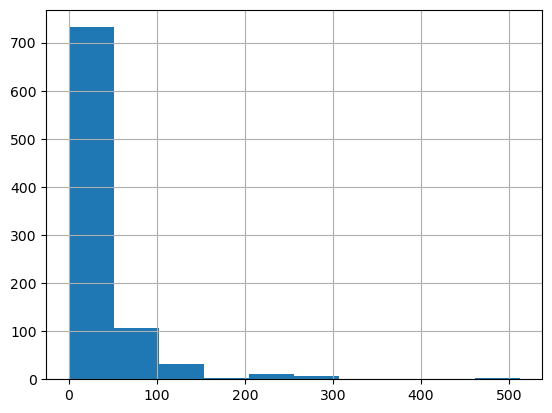

In [70]:
titanic["fare"].hist()

In [71]:
(
    titanic
    .assign(
        log_fare = lambda d: np.log(d["fare"] + 1)
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,log_fare
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,2.110213
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,4.280593
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,2.188856
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,3.990834
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,2.202765
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,2.639057
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,3.433987
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,3.196630
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,3.433987


Create a categorical variable representing fare quartiles.

We need to review ways to cut into groups, as well as quartiles.

- `pd.cut()` is the go-to for manually created bins.
- Alternatively, `np.select()` is great at case-when scenarios.
- `pd.qcut()` is good for quantile cuts (faster).
- `.quantile()`

Review `.quantile()` first. It can accept a single value or a set of values.

In [72]:
(
    titanic
    .groupby("class")
    ["fare"]
    .quantile([0, .25, .5, .75, 1])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1700244106.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


class       
Third   0.00      0.00000
        0.25      7.75000
        0.50      8.05000
        0.75     15.50000
        1.00     69.55000
Second  0.00      0.00000
        0.25     13.00000
        0.50     14.25000
        0.75     26.00000
        1.00     73.50000
First   0.00      0.00000
        0.25     30.92395
        0.50     60.28750
        0.75     93.50000
        1.00    512.32920
Name: fare, dtype: float64

> Fun illustration with .pivot (wider)

In [73]:
(
    titanic
    .groupby("class")
    ["fare"]
    .quantile([0, .25, .5, .75, 1])

    # present it
    .to_frame("value")
    .reset_index()
    .pivot(
        index="class",      # what do i want rows to be
        columns="level_1",  # what do i want to move to columns
        values="value"      # what values go in the cells
    )
    .rename_axis(columns=None, index=None)
    .round(1)
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2853939828.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,0.00,0.25,0.50,0.75,1.00
Third,0.0,7.8,8.0,15.5,69.6
Second,0.0,13.0,14.2,26.0,73.5
First,0.0,30.9,60.3,93.5,512.3


> Now that we underestand quartiles, we can see a few ways to create a quartile variable. They are:

- `pd.qcut()` (fastest)
- `pd.cut()` Slower version of same thign
- `np.select()` using a case-when style syntax

> Let's start with the slowest, and work our way to the easiest. After we do this overall, we can do by group

In [74]:
quartiles = titanic["fare"].quantile([.25, .5, .75])
(
    titanic
    .assign(
        fare_quartile = lambda d: np.select(
            [
                d["fare"] <= quartiles.iloc[0],
                d["fare"] <= quartiles.iloc[1],
                d["fare"] <= quartiles.iloc[2],
                d["fare"] > quartiles.iloc[2]
            ],
            [
                "Q1", "Q2", "Q3", "Q4"
            ],
            default="Unassigned"
        )
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_quartile
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Q1
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Q4
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Q2
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Q4
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Q2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,Q2
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,Q3
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,Q3
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,Q3


> That is great, but there is a quantile cut (`pd.qcut()`) and a generic cut (`pd.cut()`)

- The key for `pd.cut` is `bins=` and `labels=` . that's all you need. you can specify
    - `right=True` (default) → intervals (a, b].
    - `include_lowest=True` → includes the lowest boundary. THIS SHOULD BE ENABLED TO INCLUDE THE BOTTOM!!

```
pd.cut(
    df["col"],
    bins=[0, 18, 40, 60, np.inf],
    labels=["Child", "Young Adult", "Middle Aged", "Older"],
    include_lowest=True
)
```

In [75]:
pd.cut(
    titanic["age"],
    bins=[0, 18, 40, 60, np.inf],
    labels=["Child", "Young Adult", "Middle Aged", "Older"],
    include_lowest=True
)

0      Young Adult
1      Young Adult
2      Young Adult
3      Young Adult
4      Young Adult
          ...     
886    Young Adult
887    Young Adult
888            NaN
889    Young Adult
890    Young Adult
Name: age, Length: 891, dtype: category
Categories (4, object): ['Child' < 'Young Adult' < 'Middle Aged' < 'Older']

> Put it into a variable

In [76]:
(
    titanic
    .assign(
        age_group = lambda d: pd.cut(
            d["age"],
            bins=[0,18,40,60,np.inf],
            labels=["child", "adult", "midage", "old"],
            include_lowest=True
        )
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,age_group
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,adult
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,adult
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,adult
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,adult
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,adult
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,adult
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,NaN
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,adult


> Lastly, we can try `pd.qcut()` which is the simplest option here:

- col
- q (instead of bins)
- labels

In [77]:
(
    titanic
    .assign(
        fare_quartile = lambda d: pd.qcut(d["fare"], q=4, labels = ["Q1", "Q2", "Q3", "Q4"])
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_quartile
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Q1
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Q4
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Q2
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Q4
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Q2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,Q2
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,Q3
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,Q3
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,Q3


> Assume we want quartiles by class. Easy. Just put all that on a grouped series.

In [78]:
# Quantile on a grouped series -- we could make this a mapping table if we want
quantile_lookup = (
    titanic
    .groupby("class")["fare"]
    .quantile([0, .25, .5, .75, 1])
    .to_frame("value_lower")
    .reset_index()
    .assign(
        quartile = lambda d: d["level_1"].map({
            0.00: "Lower",
            0.25: "Q1", 
            0.50: "Q2",
            0.75: "Q3", 
            1.00: "Upper"
        })
    )
    .drop(columns=["level_1"])
    .assign(
        value_upper = lambda d: d["value_lower"].shift(-1)
    )
)

quantile_lookup

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2697514092.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")["fare"]


,class,value_lower,quartile,value_upper
0,Third,0.00000,Lower,7.75000
1,Third,7.75000,Q1,8.05000
2,Third,8.05000,Q2,15.50000
3,Third,15.50000,Q3,69.55000
4,Third,69.55000,Upper,0.00000
5,Second,0.00000,Lower,13.00000
6,Second,13.00000,Q1,14.25000
7,Second,14.25000,Q2,26.00000
8,Second,26.00000,Q3,73.50000
9,Second,73.50000,Upper,0.00000


> From there, we could join that onto titanic:

> In SQL, we'd match on class and match on age being within the range. Here, we have to do in two different steps.

In [79]:
(
    titanic
    .merge(
        quantile_lookup,
        on="class", 
        how="left",
        validate="many_to_many"  
    )
    .loc[lambda d: 
         (d["fare"] > d["value_lower"])
         & (d["fare"] <= d["value_upper"])
         ]
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,value_lower,quartile,value_upper
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,0.00000,Lower,7.75000
7,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,60.28750,Q2,93.50000
11,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,7.75000,Q1,8.05000
16,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,30.92395,Q1,60.28750
21,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,7.75000,Q1,8.05000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,0.00000,Lower,13.00000
4435,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,0.00000,Lower,30.92395
4443,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,15.50000,Q3,69.55000
4445,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,0.00000,Lower,30.92395


> But this is why we do NOT try to do custom logic! 

> Ideally we would Just do .groupby()--> col --> qcut() but that doesn't work on grouped series. So we need to do `.transform()`

Some things to remember about `.transform()`:
- Pattern is `d.groupby("group")["col"].transform()`
- Within `.transform()` we want to create another lambda (e.g., `lambda x:`) that lets us run our own bespoke functions, such as running `pd.qcut()`
- Within `.transform()` we always run functions that run on a series and return a series. 
    - Exception: you can pass a function that returns a scalar, and then it broadcasts
- The series it returns has indices that need to match up with the indices on the object level above, in this case `d`

In [80]:
(
    titanic
    .assign(
        fare_quartile = lambda d: 
            d.groupby("class")["fare"].transform(
                lambda x: pd.qcut(x, q=4, labels=["Q1", "Q2", "Q3", "Q4"])
            )
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/423751794.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.groupby("class")["fare"].transform(


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_quartile
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Q1
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Q3
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Q2
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Q2
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Q2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,Q1
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,Q1
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,Q4
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,Q1


# 5 - Group and Summarize

5. Group and summarize
- [ ] Calculate mean fare by passenger class.
- [ ] Calculate median age by sex.
- [ ] Calculate survival rate by sex.
- [ ] Calculate survival rate by class.
- [ ] Calculate survival rate by sex and class.
- [ ] Calculate passenger count, mean age, median fare, and survival rate by class in one operation.
- [ ] Calculate the same metrics grouped by sex and class.
- [ ] Count distinct embarkation ports represented in each class.
- [ ] Calculate the proportion of all passengers belonging to each class.
- [ ] Identify which age group had the highest survival rate.

Calculate mean fare by passenger class.

In [81]:
(
    titanic
    .groupby("class")
    .agg(
        mean_fare = ("fare", lambda d: d.mean())
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/4142994523.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,mean_fare
class,
Third,13.675550
Second,20.662183
First,84.154687


Calculate median age by sex.

In [82]:
(
    titanic
    .groupby("sex")
    .agg(
        median_age = ("age", "median")
    )
)

,median_age
sex,
female,27.0
male,29.0


Calculate survival rate by sex.

In [83]:
(
    titanic
    .groupby("sex")
    .agg(
        survival_rate = ("survived", "mean")
    )
)

,survival_rate
sex,
female,0.742038
male,0.188908


Calculate survival rate by class.

In [84]:
(
    titanic
    .groupby("class")
    .agg(
        survival_rate = ("survived", "mean")
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/394482286.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,survival_rate
class,
Third,0.242363
Second,0.472826
First,0.629630


Calculate survival rate by sex and class.

In [85]:
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        survival_rate = ("survived", "mean")
    )
    .reset_index()
    .pivot(
        index="sex",
        columns="class", 
        values="survival_rate"
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2365509753.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


class,Third,Second,First
sex,,,
female,0.500000,0.921053,0.968085
male,0.135447,0.157407,0.368852


Calculate passenger count, mean age, median fare, and survival rate by class in one operation.

In [86]:
(
    titanic
    .groupby("class")
    .agg(
        n = ("fare", "size"), #total size col is irrelevant,
        mean_age = ("age", "mean"),
        mdn_fare = ("fare", "median"),
        surv_rate = ("survived", "mean")

    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2720504168.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,n,mean_age,mdn_fare,surv_rate
class,,,,
Third,491,25.140620,8.0500,0.242363
Second,184,29.877630,14.2500,0.472826
First,216,38.233441,60.2875,0.629630


Calculate the same metrics grouped by sex and class.

In [87]:
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        n = ("fare", "size"), #total size col is irrelevant,
        mean_age = ("age", "mean"),
        mdn_fare = ("fare", "median"),
        surv_rate = ("survived", "mean")

    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1978256471.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


n   mean_age  mdn_fare  surv_rate
class  sex                                        
Third  female  144  21.750000  12.47500   0.500000
       male    347  26.507589   7.92500   0.135447
Second female   76  28.722973  22.00000   0.921053
       male    108  30.740707  13.00000   0.157407
First  female   94  34.611765  82.66455   0.968085
       male    122  41.281386  41.26250   0.368852

Count distinct embarkation ports represented in each class.

Here we use `.unique()` which is a series method, so we will use it within `.groupby()[col]`

In [88]:
titanic.groupby("class")["embarked"].unique()

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2802285954.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby("class")["embarked"].unique()


class
Third          [S, Q, C]
Second         [C, S, Q]
First     [C, S, nan, Q]
Name: embarked, dtype: object

Calculate the proportion of all passengers belonging to each class.

In [89]:
(
    titanic["class"]
    .value_counts()
    .to_frame("n")
    .assign(
        prop = titanic["class"].value_counts(normalize=True).round(2)
    )
)

,n,prop
class,,
Third,491,0.55
First,216,0.24
Second,184,0.21


Identify which age group had the highest survival rate.

> correction: class

In [90]:
(
    titanic
    .groupby("class")
    .agg(
        survival_rate = ("survived", "mean")
    )
    .sort_values("survival_rate", ascending=False)
    .iloc[0]
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1491990582.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


survival_rate    0.62963
Name: First, dtype: float64

# 6 - Group-wise transformations and window functions

6. Group-wise transformations and window functions
- [ ] Add each passenger's class-average fare as a new column without collapsing rows.
- [ ] Calculate each passenger's fare minus their class-average fare.
- [ ] Standardize fare within each passenger class (within-class z-score).
- [ ] Rank passengers by fare within each class.
- [ ] Calculate each passenger's percentile rank for fare within their class.
- [ ] Calculate cumulative fare after sorting passengers by fare.
- [ ] Calculate the difference in fare between consecutive passengers after sorting.
- [ ] Identify the top three highest-paying passengers within each class.

Add each passenger's class-average fare as a new column without collapsing rows.

> for this, we want to put in new column that is dynamically generated by group. That is the classic use of `.transform()`.

In [91]:
(
    titanic
    .assign(
        class_avg_fare = lambda d: d.groupby("class")["fare"].transform("mean")
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3525459051.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  class_avg_fare = lambda d: d.groupby("class")["fare"].transform("mean")


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,class_avg_fare
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,13.675550
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,84.154687
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,13.675550
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,84.154687
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,13.675550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,20.662183
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,84.154687
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,13.675550
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,84.154687


Calculate each passenger's fare minus their class-average fare.

> Materialize the average fare, and then subtract the user fare. Can also do in one operation but two step is easier to parse

In [92]:
(
    titanic
    .assign(
        fare_avg_by_class = lambda d: d.groupby("class")["fare"].transform("mean"),
        diff = lambda d: d["fare"] - d["fare_avg_by_class"]
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3601512839.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_avg_by_class = lambda d: d.groupby("class")["fare"].transform("mean"),


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_avg_by_class,diff
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,13.675550,-6.425550
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,84.154687,-12.871387
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,13.675550,-5.750550
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,84.154687,-31.054687
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,13.675550,-5.625550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,20.662183,-7.662183
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,84.154687,-54.154687
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,13.675550,9.774450
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,84.154687,-54.154687


Standardize fare within each passenger class (within-class z-score).

> Caution! It is very easy to accidenetally do

`fare_sd_by_class = lambda d: d.groupby("class")["fare"].std()`

instead of 

`fare_sd_by_class = lambda d: d.groupby("class")["fare"].transform("std")`

The use of `.std()` collapses it down to SD by group, which doens't work here. The use of `.transform("std")` ensures we keep the original series structure

Under the hood, the indexes have to align. That's why the series works and the SD-by-Class 3-value aggregate doesn't.

In [93]:
(
    titanic
    .assign(
        fare_avg_by_class = lambda d: d.groupby("class")["fare"].transform("mean"),
        diff = lambda d: d["fare"] - d["fare_avg_by_class"],
        fare_sd_by_class = lambda d: d.groupby("class")["fare"].transform("std"),
        z_within_class = lambda d: d["diff"] / d["fare_sd_by_class"]
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1590522840.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_avg_by_class = lambda d: d.groupby("class")["fare"].transform("mean"),
/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1590522840.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_sd_by_class = lambda d: d.groupby("class")["fare"].transform("std"),


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_avg_by_class,diff,fare_sd_by_class,z_within_class
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,13.675550,-6.425550,11.778142,-0.545549
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,84.154687,-12.871387,78.380373,-0.164217
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,13.675550,-5.750550,11.778142,-0.488239
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,84.154687,-31.054687,78.380373,-0.396205
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,13.675550,-5.625550,11.778142,-0.477626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,20.662183,-7.662183,13.417399,-0.571063
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,84.154687,-54.154687,78.380373,-0.690922
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,13.675550,9.774450,11.778142,0.829880
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,84.154687,-54.154687,78.380373,-0.690922


Rank passengers by fare within each class.

We did this earlier, but to review--we have three options.

Within class, we can
- Use `.rank()`
- Use `.cumcount()+1`

For us, `.rank()` is great.

In [94]:
(
    titanic
    .assign(
        fare_rank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False)
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3122617636.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_rank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False)


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_rank_within_class
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,421.0
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,98.0
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,263.0
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,121.0
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,219.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,142.0
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,173.0
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,66.0
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,174.0


Calculate each passenger's percentile rank for fare within their class.

> `pct = True` is a great option for percentile rank

In [95]:
(
    titanic
    .assign(
        fare_rank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False),
        pct_fare_rank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False, pct=True)
    )
    .sort_values(["class", "pct_fare_rank_within_class"], ascending=[False, False])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/633843709.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fare_rank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False),
/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/633843709.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pct_fare_rank_within_class = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False, pct=True)


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_rank_within_class,pct_fare_rank_within_class
822,822,0,1,male,38.0,0,0,0.00,S,First,man,True,NaN,Southampton,no,True,216.0,1.000000
815,815,0,1,male,NaN,0,0,0.00,S,First,man,True,B,Southampton,no,True,215.0,0.995370
806,806,0,1,male,39.0,0,0,0.00,S,First,man,True,A,Southampton,no,True,214.0,0.990741
633,633,0,1,male,NaN,0,0,0.00,S,First,man,True,NaN,Southampton,no,True,213.0,0.986111
263,263,0,1,male,40.0,0,0,0.00,S,First,man,True,B,Southampton,no,True,212.0,0.981481
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
792,792,0,3,female,NaN,8,2,69.55,S,Third,woman,False,NaN,Southampton,no,False,5.0,0.010183
324,324,0,3,male,NaN,8,2,69.55,S,Third,man,True,NaN,Southampton,no,False,4.0,0.008147
201,201,0,3,male,NaN,8,2,69.55,S,Third,man,True,NaN,Southampton,no,False,3.0,0.006110
180,180,0,3,female,NaN,8,2,69.55,S,Third,woman,False,NaN,Southampton,no,False,2.0,0.004073


Calculate cumulative fare after sorting passengers by fare.

In [96]:
(
    titanic
    .sort_values("fare", ascending=False)
    .assign(
        cumfare = lambda d: d["fare"].cumsum()
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,cumfare
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,512.3292
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,1024.6584
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,1536.9876
88,88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,1799.9876
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,2062.9876
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,633,0,1,male,NaN,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True,28693.9493
413,413,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,28693.9493
822,822,0,1,male,38.0,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True,28693.9493
732,732,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,28693.9493


Calculate the difference in fare between consecutive passengers after sorting.

In [97]:
(
    titanic
    .sort_values("fare", ascending=False)
    .assign(
        fare_diff = lambda d: d["fare"] - d["fare"].shift(1)
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,fare_diff
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,NaN
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,0.0000
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,0.0000
88,88,1,1,female,23.0,3,2,263.0000,S,First,woman,False,C,Southampton,yes,False,-249.3292
27,27,0,1,male,19.0,3,2,263.0000,S,First,man,True,C,Southampton,no,False,0.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
633,633,0,1,male,NaN,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True,0.0000
413,413,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,0.0000
822,822,0,1,male,38.0,0,0,0.0000,S,First,man,True,NaN,Southampton,no,True,0.0000
732,732,0,2,male,NaN,0,0,0.0000,S,Second,man,True,NaN,Southampton,no,True,0.0000


Identify the top three highest-paying passengers within each class.

- `.head()`
- `.rank()`
- `.cumcount() + 1`

In [98]:
(
    titanic
    .sort_values("fare", ascending=False)
    .groupby("class")
    .head(3)
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2564580678.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False
655,655,0,2,male,24.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False
385,385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True
72,72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True
863,863,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False
324,324,0,3,male,NaN,8,2,69.5500,S,Third,man,True,NaN,Southampton,no,False
180,180,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False


In [99]:
(
    titanic
    .sort_values("fare", ascending=False)
    .assign(
        rows = lambda d: d.groupby("class")["fare"].cumcount() + 1
    )
    .loc[lambda d: d["rows"] <= 3]
    .sort_values(["class", "rows"], ascending=[False, True])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2548422392.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rows = lambda d: d.groupby("class")["fare"].cumcount() + 1


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,rows
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,1
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,2
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,3
655,655,0,2,male,24.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,1
385,385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,2
72,72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,3
863,863,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False,1
324,324,0,3,male,NaN,8,2,69.5500,S,Third,man,True,NaN,Southampton,no,False,2
180,180,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False,3


In [100]:
(
    titanic
    .assign(
        ranking = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False)
    )
    .loc[lambda d: d["ranking"] <= 3]
    .sort_values(["class", "fare"], ascending=[False, True])
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3699553698.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ranking = lambda d: d.groupby("class")["fare"].rank(method="first", ascending=False)


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,ranking
258,258,1,1,female,35.0,0,0,512.3292,C,First,woman,False,NaN,Cherbourg,yes,True,1.0
679,679,1,1,male,36.0,0,1,512.3292,C,First,man,True,B,Cherbourg,yes,False,2.0
737,737,1,1,male,35.0,0,0,512.3292,C,First,man,True,B,Cherbourg,yes,True,3.0
72,72,0,2,male,21.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,1.0
120,120,0,2,male,21.0,2,0,73.5000,S,Second,man,True,NaN,Southampton,no,False,2.0
385,385,0,2,male,18.0,0,0,73.5000,S,Second,man,True,NaN,Southampton,no,True,3.0
159,159,0,3,male,NaN,8,2,69.5500,S,Third,man,True,NaN,Southampton,no,False,1.0
180,180,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False,2.0
201,201,0,3,male,NaN,8,2,69.5500,S,Third,man,True,NaN,Southampton,no,False,3.0


> Some key things to remember:
- `.cumcount()` is not smart. You have to pre-sort. 
- `.head()` is the same
- `.rank()` is indeed smart. no need to presort

For all of these, you use `.groupby()` within assign. This is not R.

# 7 - Pivot and reshape

7. Pivot and reshape
- [ ] Create a survival-rate table with class as rows and sex as columns.
- [ ] Create a passenger-count table with class as rows and embarkation port as columns.
- [ ] Create a pivot table showing mean age by sex and survival status.
- [ ] Create a pivot table with multiple summary statistics for fare.
- [ ] Convert a wide summary table into long format.
- [ ] Convert that long table back into wide format.
- [ ] Create a contingency table of sex × survival.
- [ ] Create a contingency table of class × survival with row percentages.

Things we will want here in clude
- .groupby().agg() .... grouped summaries in long format
- .pivot_table() .... summaries with groups as ROWS AND COLUMNS. similar to summarize and then pivot_wider() in R
- . pd.crosstab() .... similar to table() or prop.table() in R
- .melt() .... wide to long... pivot_longer()
- .pivot() .... long to wide WITHOUT AGGREGATION ...pivot_wider()
- .unstack .... move an index level into columns ... similar ot pivot_wider()
- .stack .... move a column intoa n index level ... similar to pivot_longer()

for a summary matrix, the pattern is:
```
df.pivot_table()
    index="row_category",       # one analysis column
    columns="column_category",  # one analysis column
    values="measurement",       # the VALUE 
    aggfunc="mean"              # what we are using as the function
```

In [101]:
#example

titanic.pivot_table(
    index = "class",
    columns="embarked",
    values="survived",
    aggfunc=lambda d: d.mean()
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2919797295.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  titanic.pivot_table(


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


In [102]:
# also easy to do that in long format and pivot wider
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        mean_survival = ("survived", lambda d: d.mean())
    )
    .unstack("embarked")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/493661564.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


mean_survival                    
embarked             C         Q         S
class                                     
Third         0.378788  0.375000  0.189802
Second        0.529412  0.666667  0.463415
First         0.694118  0.500000  0.582677

In [103]:
# or we can pivot wider with .pivot
# trick is that index needs to move into data
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        mean_survival = ("survived", lambda d: d.mean())
    )
    .reset_index()
    .pivot(
        index="class",
        columns="embarked",
        values="mean_survival"
    )
)


/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/188091829.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


for crosstabs, the pattern is
```
pd.crosstab(
    df["row_category"],
    df["column_category"],
    normalize="index"|"columns"|"all"
)
```

- omit normalize for counts
- normalize can be 
    - "index" for row props
    - "columns" for col props
    - "all" for overall proportions


for wide --> long

```
df.melt(
    id_vars=["cols_identifying_rows"], #current rows
    value_vars=["measure_a", "measure_b"], #current inputs
    var_name = "old_varnames_as_var",   # new place to put intput names
    value_name = "old_values_as_var"    # new place to put value names
)
```
for long --> wide

```
df.pivot(
    index="identifier", # keep as rows
    columns="measure", #this will turn into new columns
    values="value"
)
```

Special case --- if you have nested indexes, you can pivot one of them into columns with unstack

In [104]:
#example of unstack
eg_series = (
    titanic.groupby(["class", "embarked"])["fare"].mean()
)
eg_series

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1755832444.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(["class", "embarked"])["fare"].mean()


class   embarked
Third   C            11.214083
        Q            11.183393
        S            14.644083
Second  C            25.358335
        Q            12.350000
        S            20.327439
First   C           104.718529
        Q            90.000000
        S            70.364862
Name: fare, dtype: float64

In [105]:
#We can easily pivot that wider with unstack
eg_series.unstack("class")

class,Third,Second,First
embarked,,,
C,11.214083,25.358335,104.718529
Q,11.183393,12.350000,90.000000
S,14.644083,20.327439,70.364862


In [106]:
eg_series.unstack("class")

class,Third,Second,First
embarked,,,
C,11.214083,25.358335,104.718529
Q,11.183393,12.350000,90.000000
S,14.644083,20.327439,70.364862


Lets' do a simple melt

In [107]:
#first make a ide dataframe
temp1 = (
    titanic
    .groupby(["class", "sex"])
    .agg(
        npass = ("class", lambda d: len(d))
    )
    .reset_index()
    .pivot(
        index="class",
        columns=["sex"],
        values="npass",
        )
)
display(temp1)

#make it longer

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2430329758.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


sex,female,male
class,,
Third,144,347
Second,76,108
First,94,122


In [108]:
# melt it

(
    temp1
    .reset_index()
    .melt(
        id_vars=["class"], #what identifies rows
        value_vars = ["female", "male"],
        var_name="sex",
        value_name = "count"
    )
    
)

,class,sex,count
0,Third,female,144
1,Second,female,76
2,First,female,94
3,Third,male,347
4,Second,male,108
5,First,male,122


Practice! first, use multiple columns to go wide, then make longer with a melt

In [109]:
#first make a ide dataframe
temp1 = (
    titanic
    .groupby(["class", "sex", "embarked"])
    .agg(
        npass = ("class", lambda d: len(d))
    )
    .reset_index()
    .pivot(
        index="class",
        columns=['embarked', "sex"],
        values="npass",
        )
)
display(temp1)

#make it longer

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/207802974.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex", "embarked"])


embarked,C,Q,S,C,Q,S
sex,female,female,female,male,male,male
class,,,,,,
Third,23,33,88,43,39,265
Second,7,2,67,10,1,97
First,43,1,48,42,1,79


In [110]:
# method 1 = stack
(
    temp1
    .stack("sex")   
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1855840810.py:4: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack("sex")


embarked        C   Q    S
class  sex                
Third  female  23  33   88
       male    43  39  265
Second female   7   2   67
       male    10   1   97
First  female  43   1   48
       male    42   1   79

In [111]:
# you can also 
# method 1 = stack
(
    temp1
    .stack("sex")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2602865544.py:5: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack("sex")


embarked        C   Q    S
class  sex                
Third  female  23  33   88
       male    43  39  265
Second female   7   2   67
       male    10   1   97
First  female  43   1   48
       male    42   1   79

In [112]:
temp1

embarked,C,Q,S,C,Q,S
sex,female,female,female,male,male,male
class,,,,,,
Third,23,33,88,43,39,265
Second,7,2,67,10,1,97
First,43,1,48,42,1,79


In [113]:
(
    temp1
    .rename_axis(columns=["embarked", "sex"])
    .reset_index()
    )

embarked,class,C,Q,S,C,Q,S
sex,,female,female,female,male,male,male
0,Third,23,33,88,43,39,265
1,Second,7,2,67,10,1,97
2,First,43,1,48,42,1,79


In [114]:
# method 2 = melt
# too complex!

Now for test questions!

Create a survival-rate table with class as rows and sex as columns.

In [115]:
# method 1 - long format first, then pivot wider
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        surv = ("survived", lambda d: d.mean())
    )
    .unstack("sex")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2429240955.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


surv          
sex       female      male
class                     
Third   0.500000  0.135447
Second  0.921053  0.157407
First   0.968085  0.368852

In [116]:
# method 2 - same thing but with pivot wider ... get indexes into df first
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        surv = ("survived", lambda d: d.mean())
    )
    .reset_index()
    .pivot(
        index="class",
        columns="sex",
        values="surv"
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2532384574.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


sex,female,male
class,,
Third,0.500000,0.135447
Second,0.921053,0.157407
First,0.968085,0.368852


In [117]:
# method 3 - pivot table
(
    titanic
    .pivot_table(
        index="class",
        columns="embarked",
        values="survived",
        aggfunc = lambda d: d.mean()
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/446696868.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


Create a passenger-count table with class as rows and embarkation port as columns.

In [118]:
# method 1a -- same as above 3 methods, but with a .size()
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        passengers = ("class", lambda d: len(d))
    )
    .unstack("embarked")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/325420583.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


passengers         
embarked          C   Q    S
class                       
Third            66  72  353
Second           17   3  164
First            85   2  127

In [119]:
#method 1b - with pivot
(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        passengers = ("class", lambda d: len(d)) #dummy variable sinc we are counting people
    )
    .reset_index()
    .pivot(
        index="class",
        columns="embarked",
        values="passengers"
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/822732678.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


embarked,C,Q,S
class,,,
Third,66,72,353
Second,17,3,164
First,85,2,127


In [120]:
# method 1c - with pivot table
(
    titanic
    .pivot_table(
        index="class",
        columns="embarked",
        values="fare", #dummy variable since we are counting people
        aggfunc=lambda d: len(d)
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1497665816.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


embarked,C,Q,S
class,,,
Third,66,72,353
Second,17,3,164
First,85,2,127


In [121]:
# Method 2 - crosstabs

pd.crosstab(
    index=titanic["class"],
    columns=titanic["embarked"]
)

embarked,C,Q,S
class,,,
Third,66,72,353
Second,17,3,164
First,85,2,127


Create a pivot table showing mean age by sex and survival status.

In [122]:
(
    titanic
    .pivot_table(
        index="sex",
        columns="survived",
        values="age",
        aggfunc=lambda d: d.mean()
    )
)

survived,0,1
sex,,
female,25.046875,28.847716
male,31.618056,27.276022


In [123]:
# for fun, renaming
(
    titanic
    .pivot_table(
        index="sex",
        columns="survived",
        values="age",
        aggfunc=lambda d: d.mean()
    )
    .reset_index()
    .rename(columns={
        0: "Did Not Survive",
        1: "Survived",
        "sex": "Sex"
        })
    .rename_axis(index=None, columns=None)
    .assign(
        Sex = lambda d: d["Sex"].map({"female": "Female", "male": "Male"})
    )
    .round(2)
)

,Sex,Did Not Survive,Survived
0,Female,25.05,28.85
1,Male,31.62,27.28


Create a pivot table with multiple summary statistics for fare.

In [124]:
# manual control with .agg

(
    titanic
    .groupby(["class", "embarked"])
    .agg(
        mean = ("fare", lambda d: d.mean()),
        median = ("fare", lambda d: d.median()),
        std = ("fare", lambda d: d.std()),
        n = ("fare", lambda d: d.size),     #NO PAREN ON SIZE!!
        min = ("fare", lambda d: min(d)),
        max = ("fare", lambda d: max(d))
    )
    .round(2)
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3868165051.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "embarked"])


mean  median    std    n    min     max
class  embarked                                           
Third  C          11.21    7.90   4.87   66   4.01   22.36
       Q          11.18    7.75   6.72   72   6.75   29.12
       S          14.64    8.05  13.28  353   0.00   69.55
Second C          25.36   24.00  11.35   17  12.00   41.58
       Q          12.35   12.35   0.00    3  12.35   12.35
       S          20.33   13.50  13.63  164   0.00   73.50
First  C         104.72   78.27  99.09   85  26.55  512.33
       Q          90.00   90.00   0.00    2  90.00   90.00
       S          70.36   52.00  58.81  127   0.00  263.00

Convert a wide summary table into long format.

In [125]:
temp1 = (
    titanic
    .pivot_table(
        index="class",
        columns = "embarked",
        values = "survived",
        aggfunc = lambda d: d.mean()
    )
)
display(temp1)

display(
    temp1
    .stack("embarked")
    )


temp2 = (
    temp1
    .reset_index()
    .melt(
        id_vars="class",
        value_vars=["C", "Q", "S"],
        value_name = "survival_rate",
        var_name = "Embarked"
    )
)

display(temp2)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1952040201.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  .pivot_table(


embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


class   embarked
Third   C           0.378788
        Q           0.375000
        S           0.189802
Second  C           0.529412
        Q           0.666667
        S           0.463415
First   C           0.694118
        Q           0.500000
        S           0.582677
dtype: float64

,class,Embarked,survival_rate
0,Third,C,0.378788
1,Second,C,0.529412
2,First,C,0.694118
3,Third,Q,0.375000
4,Second,Q,0.666667
5,First,Q,0.500000
6,Third,S,0.189802
7,Second,S,0.463415
8,First,S,0.582677


In [126]:
#get temp2 back to wide

(
    temp2
    .pivot(
        index="class",
        columns="Embarked",
        values="survival_rate"
    )
    )

Embarked,C,Q,S
class,,,
Third,0.378788,0.375000,0.189802
Second,0.529412,0.666667,0.463415
First,0.694118,0.500000,0.582677


Create a contingency table of sex × survival.

In [127]:
pd.crosstab(
    index=titanic["sex"],
    columns=titanic["survived"]
)

survived,0,1
sex,,
female,81,233
male,468,109


Create a contingency table of class × survival with row percentages.

In [128]:
pd.crosstab(
    index=titanic["class"],
    columns=titanic["survived"]
)

survived,0,1
class,,
Third,372,119
Second,97,87
First,80,136


Bonus: crosstab with multiple variables

In [129]:
pd.crosstab(
    index=[
        titanic["class"],
        titanic["sex"]
    ],
    columns=titanic["survived"]
)

survived         0   1
class  sex            
Third  female   72  72
       male    300  47
Second female    6  70
       male     91  17
First  female    3  91
       male     77  45

# 8 - Joins and combining data

8. Joins and combining data
- [ ] Create a separate DataFrame containing mean fare by class.
- [ ] Left-join that summary back onto the passenger-level dataset.
- [ ] Verify the join did not unexpectedly increase the number of rows.
- [ ] Create a lookup table mapping embarkation codes to port names.
- [ ] Join the lookup table to the passenger dataset.
- [ ] Practice inner, left, right, and outer joins using small subsets.
- [ ] Split the dataset into male and female passengers, then concatenate them back together.
- [ ] Identify unmatched rows after a join.

Core playbook

- `.merge()` or `pd.merge()` joins dataframe using keys
- `.join()` joins dataframe using index values
- `pd.concat([a, b], axis=0|1, ignore_index=True)` 

```
df1.merge(
    df2,
    on="key", #or [key1, key2] for multi-key-joins
    how="left"|"right"|"inner"|"outer",
    validate="X_to_X", #X can be many or one
    indicator=True #column to say if row matched
)
```

if differnet names:
`left_on=` and `right_on=`

indicator gives a `_merge` column indicating which joined ("both" "left_only" "right_only)

Join by key
`df1.merge(df2, on="key", how="left")`

Join using multiple keys
`df1.merge(df2, on=["key1", "key2"])`

Protect against accidental duplicate matches
`df1.merge(df2, on="key", validate="many_to_one")`

Diagnose unmatched records
`df1.merge(df2, on="key", how="left", indicator=True)`

Stack rows
`pd.concat([df1, df2], ignore_index=True)`

Combine columns (by index)
`pd.concat([df1, df2], axis=1)`

Map lookup values
`df["code"].map(mapping_dict)`

Check unique keys
`df["key"].is_unique`

Check duplicate keys
`df.duplicated(subset=["key"]).sum()`

Some simple mapping without a join

In [130]:
# sipmly recode an existing variable with a dict!
(
    titanic
    .assign(
        port_name = lambda d: d["embarked"].map({"C": "Cherbourg", "S": "Southampton", "Q": "Queenstown"})
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,port_name
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Southampton
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Cherbourg
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Southampton
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Southampton
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Southampton
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,Southampton
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,Southampton
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,Southampton
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,Cherbourg


Now to test questions

Create a separate DataFrame containing mean fare by class.

In [131]:
df1 = (
    titanic
    .groupby("class")
    .agg(
        mean_fare_by_class = ("fare", "mean")
    )
)

df1

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1213143968.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,mean_fare_by_class
class,
Third,13.675550
Second,20.662183
First,84.154687


Left-join that summary back onto the passenger-level dataset.

In [132]:
joined = (
    titanic
    .merge(
        df1, 
        on="class",
        how="left",
        validate="many_to_one"
    )
)

joined

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,mean_fare_by_class
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,13.675550
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,84.154687
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,13.675550
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,84.154687
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,13.675550
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,20.662183
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,84.154687
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,13.675550
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,84.154687


In [133]:
assert len(joined) == len(titanic)

Create a lookup table mapping embarkation codes to port names. Then, join to passenger data

In [134]:
ports = pd.DataFrame({
    "port": ["Queensland", "Southampton", "Cherbourg",],
    "Embarked": ["Q", "S", "C"]
    })

ports

,port,Embarked
0,Queensland,Q
1,Southampton,S
2,Cherbourg,C


In [135]:
(
    titanic
    .merge(
        ports, 
        left_on="embarked", 
        right_on="Embarked",
        how="left",
        validate="many_to_one"
    )
)

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,port,Embarked
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,Southampton,S
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,Cherbourg,C
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,Southampton,S
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,Southampton,S
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,Southampton,S
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,Southampton,S
887,887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,Southampton,S
888,888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,Southampton,S
889,889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,Cherbourg,C


Split the dataset into male and female passengers, then concatenate them back together.

In [136]:
male = (
    titanic.loc[titanic["sex"]=="male"]
)

female = (
    titanic.loc[titanic["sex"]=="female"]
)

print(male.shape)
print(female.shape)

(577, 16)
(314, 16)


In [137]:
output = pd.concat(
    [male, female], axis=0
).sort_index() #puts back in row order
assert output.equals(titanic)

Identify unmatched rows after a join.

In [138]:
# incomplete lookup table

ports_bad = pd.DataFrame({
    "port": ["Cherbourg", "Southampton"],
    "embarked": ["C", "S"]
})

test_df = (
    titanic
    .merge(ports_bad, how="left", on="embarked", validate="many_to_one", indicator=True)
)

assert(titanic.shape[0] == test_df.shape[0])

test_df.loc[test_df["_merge"] != "both" ]

,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,port,_merge
5,5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True,NaN,left_only
16,16,0,3,male,2.0,4,1,29.1250,Q,Third,child,False,NaN,Queenstown,no,False,NaN,left_only
22,22,1,3,female,15.0,0,0,8.0292,Q,Third,child,False,NaN,Queenstown,yes,True,NaN,left_only
28,28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True,NaN,left_only
32,32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True,NaN,left_only
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
825,825,0,3,male,NaN,0,0,6.9500,Q,Third,man,True,NaN,Queenstown,no,True,NaN,left_only
828,828,1,3,male,NaN,0,0,7.7500,Q,Third,man,True,NaN,Queenstown,yes,True,NaN,left_only
829,829,1,1,female,62.0,0,0,80.0000,NaN,First,woman,False,B,NaN,yes,True,NaN,left_only
885,885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False,NaN,left_only


In [139]:
titanic["fare"].to_frame("fare")

,fare
0,7.2500
1,71.2833
2,7.9250
3,53.1000
4,8.0500
...,...
886,13.0000
887,30.0000
888,23.4500
889,30.0000


# Test Questions


9. Missing-data and quality checks
- [ ] Compare mean age before and after imputation.
- [ ] Calculate missing-age percentages by sex and class using the original data.
- [ ] Identify columns with more than 20% missing values.
- [ ] Check for impossible ages or negative fares.
- [ ] Check that survived contains only 0 and 1.
- [ ] Check whether family_size is always at least 1.
- [ ] Confirm that no unexpected rows were lost during transformations.
- [ ] Create a final analysis-ready DataFrame containing only the variables needed for modeling.
10. Interview-style challenges
- [ ] Find the passenger class with the highest survival rate among children.
- [ ] Find the sex × class combination with the largest number of passengers.
- [ ] Calculate the difference in survival rates between men and women within each class.
- [ ] Identify passengers whose fare exceeds twice the median fare of their class.
- [ ] Calculate the proportion of passengers traveling alone within each class.
- [ ] Find the three age groups with the highest average fare.
- [ ] Produce a single summary table containing passenger counts, survival rates, average age, median fare, and percentage traveling alone, grouped by sex and class.

## 9 - Missing Data Test Questions

Compare mean age before and after imputation.

Key to doing this is that `age_imputed` lambda d ... rembember you can reference d inside of the fillna also

In [140]:
# original
raw_age = titanic["age"].mean()
print(raw_age)

# impute class-median age for missings
imputed = \
(
    titanic
    .assign(
        age_imputed = lambda d: d["age"].fillna(
            d.groupby("class")["age"].transform("mean")
        )
    )
)

imputed_age = imputed["age_imputed"].mean()
print(imputed_age)

29.69911764705882
29.292874790272087


/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3137700744.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d.groupby("class")["age"].transform("mean")


Calculate missing-age percentages by sex and class using the original data.

Friendly reminder! 

- When using `.assign()` you want to `.groupby()` WITHIN the calculations. 
- When using `.agg()` you want to groupby BEFORE the agg.

In [141]:
(
    titanic_raw
    .groupby(["class", "sex"])
    .agg(
        missing_pct_age = ("age", lambda d: d.isna().sum() / len(d)),
    )
)

missing_pct_age
class  sex                    
First  female         0.095745
       male           0.172131
Second female         0.026316
       male           0.083333
Third  female         0.291667
       male           0.270893

Identify columns with more than 20% missing values.

Critical! You can run statistical functions over entire dataframes (e.g., `.sum()`). 

A mental model is that 
- They default to veritcal (e.g., `.sum()` is effectively column sums)
- You can sepcify `axis=1` to sum across COLUMNS instead (e.g., row sums)
- `numeric_only = True` lets us loop over only the numeric columns

In [142]:
(
    titanic
    .isna()
    .sum()
    .to_frame("n_missing")
    .assign(
        pct = lambda d: d["n_missing"] / len(titanic)
    )
    .sort_values("pct", ascending=False)
    .loc[lambda d: d["pct"] >= .20]

)

,n_missing,pct
deck,688,0.772166


> Illustrating those features

In [143]:
(
    titanic
    .mean(
        numeric_only = True
    )
)

personid      445.000000
survived        0.383838
pclass          2.308642
age            29.699118
sibsp           0.523008
parch           0.381594
fare           32.204208
adult_male      0.602694
alone           0.602694
dtype: float64

Check for impossible ages or negative fares.

<Axes: >

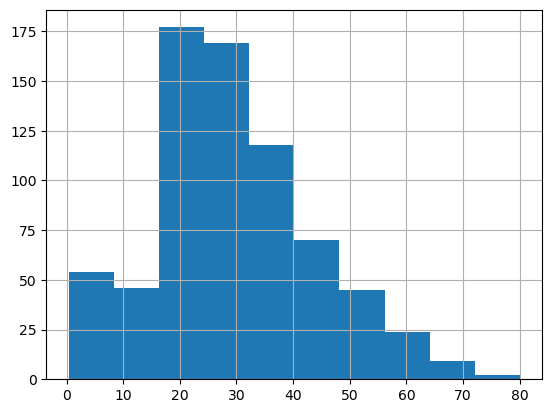

In [144]:
titanic["age"].hist()

In [145]:
titanic["age"].describe()

count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: age, dtype: float64

In [146]:
(
    titanic
    .assign(
        neg_fare = lambda d: d["fare"] < 0
    )
    ["neg_fare"].sum()
)

np.int64(0)

Check that survived contains only 0 and 1.

For this one, let's try grabbing the indexes from a value_counts

We can do a set comparison. Recall that comparisons of sets are "superset" and "subset" comparisons. We want to assert that the set of indexes is equal to or smaller than {0,1}

In [147]:
idx = titanic["survived"].value_counts().index.to_list()

assert set(idx) <= {0, 1}

> That was a complicated way to get the values in the data. We can also just take the set of the raw data, making sure we don't bring over missing values. 

In [148]:
assert set(titanic["survived"].dropna()) <= {0,1}

Check whether family_size is always at least 1.

In [149]:
temp = (
    titanic
    .assign(
        family_size = lambda d: 1 + d["sibsp"] + d["parch"]
    )
)

# min value is 1 or greater
assert min(temp["family_size"]) >= 1

Confirm that no unexpected rows were lost during transformations.

In [150]:
assert len(titanic) == len(titanic_raw)

## 10 - Real Test Questions

Find the passenger class with the highest survival rate among children.

Logic: 
- First, filter to children
    - in a novel dataset, good to check this data is clean
- Then calculate survival rate of children by class (agg)
    - in a novel dataset, good to check this data is clean
- Sort by highest rate
- Return corresponding class

In [151]:
(
    titanic
    .loc[lambda d: d["age"] <= 18]
    .groupby("class")
    .agg(
        survival_rate = ("survived", "mean")
    )
    .sort_values("survival_rate", ascending=False)
    .reset_index()
    .iloc[0,0]
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3510920076.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


'First'

Find the sex × class combination with the largest number of passengers.

Logic: 
- get a crostab to get all the combinations
- Melt it to long
- Sort and grab value

In [152]:
(
    pd.crosstab(
        index=titanic["sex"],
        columns=titanic["class"]
    )
    .stack("class")
    .to_frame("n")
    .sort_values("n", ascending=False)
    .iloc[0]
)

n    347
Name: (male, Third), dtype: int64

> That's fine, but we can also get it using the `.size()` series method:

In [153]:
(
    titanic
    .groupby(["class", "sex"])
    .agg(
        n_pass = ("class", "size")
    )
    .sort_values("n_pass", ascending=False)
    .iloc[0]
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2800668850.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["class", "sex"])


n_pass    347
Name: (Third, male), dtype: int64

> And dont' forget we can always skip the data frame and do the series directly:

In [154]:
titanic.groupby(["sex", "class"]).size()

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/2473697137.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  titanic.groupby(["sex", "class"]).size()


sex     class 
female  Third     144
        Second     76
        First      94
male    Third     347
        Second    108
        First     122
dtype: int64

Calculate the difference in survival rates between men and women within each class.


Logic: 
- survival rates by sex and class are easy to create
    - since this is an aggregation, group by BEFORE the calculation
- pivot wider to create m/f columns
- diff them

In [155]:
(
    titanic
    .groupby(["sex", "class"])
    .agg(
        surv = ("survived", "mean")
    )
    .reset_index()
    .pivot(
        index="class",
        columns="sex",
        values = "surv"
    )
    .assign(
        sex_diff = lambda d: d["male"] - d["female"]
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3569817689.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["sex", "class"])


sex,female,male,sex_diff
class,,,
Third,0.500000,0.135447,-0.364553
Second,0.921053,0.157407,-0.763645
First,0.968085,0.368852,-0.599233


> Cautionary note on the above. It's tempting to want to use `.unstack()` for rapid pivot to wide. However, you get a multi-index scenario.

In [156]:
(
    titanic
    .groupby(["sex", "class"])
    .agg(
        surv = ("survived", "mean")
    )
    .unstack("sex")
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1925088389.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["sex", "class"])


surv          
sex       female      male
class                     
Third   0.500000  0.135447
Second  0.921053  0.157407
First   0.968085  0.368852

> In that scenario, we need to flatten the hierarchical multiindex columns. In general, it is easier to manipulate data than indexes, which was why i went with a pivot. 

> We can flatten the hierarhical index with `.droplevel()` where we set it to level 0 and say we want to apply this to columns (`axis = 1`)

In [157]:
(
    titanic
    .groupby(["sex", "class"])
    .agg(
        surv = ("survived", "mean")
    )
    .unstack("sex")

    #flatten level of axis: 
    .droplevel(0, axis=1)

    .assign(
        sex_diff = lambda d: d["male"] - d["female"]
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/4035375937.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["sex", "class"])


sex,female,male,sex_diff
class,,,
Third,0.500000,0.135447,-0.364553
Second,0.921053,0.157407,-0.763645
First,0.968085,0.368852,-0.599233


Identify passengers whose fare exceeds twice the median fare of their class.

Logic: 

- Populate median fare by group as a person-level variable
- Compare against that value
- filter 

In [158]:
(
    titanic
    .assign(
        median_fare_by_class = lambda d: d.groupby("class")["fare"].transform("median"),
        above_2x_class_mdn = lambda d: d["fare"] > (2 * d["median_fare_by_class"])
    )
    .loc[lambda d: d["above_2x_class_mdn"] == True]
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/3479109032.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median_fare_by_class = lambda d: d.groupby("class")["fare"].transform("median"),


,personid,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,median_fare_by_class,above_2x_class_mdn
7,7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False,8.0500,True
9,9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False,14.2500,True
10,10,1,3,female,4.0,1,1,16.7000,S,Third,child,False,G,Southampton,yes,False,8.0500,True
13,13,0,3,male,39.0,1,5,31.2750,S,Third,man,True,NaN,Southampton,no,False,8.0500,True
16,16,0,3,male,2.0,4,1,29.1250,Q,Third,child,False,NaN,Queenstown,no,False,8.0500,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
856,856,1,1,female,45.0,1,1,164.8667,S,First,woman,False,NaN,Southampton,yes,False,60.2875,True
858,858,1,3,female,24.0,0,3,19.2583,C,Third,woman,False,NaN,Cherbourg,yes,False,8.0500,True
863,863,0,3,female,NaN,8,2,69.5500,S,Third,woman,False,NaN,Southampton,no,False,8.0500,True
885,885,0,3,female,39.0,0,5,29.1250,Q,Third,woman,False,NaN,Queenstown,no,False,8.0500,True


Calculate the proportion of passengers traveling alone within each class.

logic:
- You are traveling alone if sibsp and parch are both 0
- group by class --> agg to prop

In [159]:
(
    titanic
    .assign(
        travel_alone = lambda d: (d["parch"] == 0) & (d["sibsp"] == 0)
    )
    .groupby("class")
    .agg(
        prop = ("travel_alone", "mean" )
    )
)

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/4175657888.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("class")


,prop
class,
Third,0.659878
Second,0.565217
First,0.504630


Find the three age groups with the highest average fare.

Logic:
- Create age groups. For this exercise, assume we decided we had 6 groups.
- Aggregate to average fare per group
- sort
- Find top 3 rows

In [160]:
(
    titanic
    .assign(
        age_group = lambda d: np.select(
            [
                d["age"] < 13,
                d["age"] < 18,
                d["age"] < 35,
                d["age"] < 50,
                d["age"] < 65,
                d["age"] >= 65

            ],
            [
                "Child - Preteen",
                "Child - Teen",
                "Young Adult",
                "Middle Aged",
                "Older Adult",
                "Elderly"
            ],
            default="Unassigned"
        )
    )
    .loc[lambda d: d["age_group"] != "Unassigned"]
    .groupby("age_group")
    .agg(
        mean_fare = ("fare", "mean"),
        n = ("fare", "count")
    )
    .sort_values("mean_fare", ascending=False)
    .head(3)
)

,mean_fare,n
age_group,,
Older Adult,49.412763,63
Middle Aged,47.934524,161
Child - Preteen,31.536352,69


Produce a single summary table containing passenger counts, survival rates, average age, median fare, and percentage traveling alone, grouped by sex and class.

Logic:
- All of these are single-number summaries (aggregations) over a grouping.
- Need to re-create travling alone
- Straighforward gropuby --> agg

In [161]:
(
    titanic
    .assign(
        travel_alone = lambda d: (d["parch"] == 0) & (d["sibsp"] == 0)
    )
    .groupby(["sex", "class"], observed=True)
    .agg(
        n_pass = ("class", "size"), #dummy var, size includes missings which is ok here
        surv_rate = ("survived", "mean"),
        mean_age = ("age", "mean"),
        median_fare = ("fare", "median"),
        travel_alone_rate = ("travel_alone", "mean")
    )
    .reset_index()
    .round(2)
)

,sex,class,n_pass,surv_rate,mean_age,median_fare,travel_alone_rate
0,female,Third,144,0.50,21.75,12.48,0.42
1,female,Second,76,0.92,28.72,22.00,0.42
2,female,First,94,0.97,34.61,82.66,0.36
3,male,Third,347,0.14,26.51,7.92,0.76
4,male,Second,108,0.16,30.74,13.00,0.67
5,male,First,122,0.37,41.28,41.26,0.61


# Regression Practice

We can run ols easily with `smf.ols()`

Only two arguments:
- formula
- data

The formula syntax is easy:

    formula="fare ~ age + C(sex) + C(pclass)",

The C() tells statsmodels to treat a variable as categorical. I'm using pclass rather than class because class is a Python keyword and can cause problems in formulas.

In [162]:
import statsmodels.formula.api as smf

titanic_ds = (
    titanic
        .assign(family_size = lambda d: 1 + d["sibsp"] + d["parch"] )
        .rename(columns={"class": "ship_class"})
        )

mod = smf.ols(
    formula = "family_size ~ C(ship_class)",
    data = titanic_ds
).fit()

Let's review results!

In [163]:
print(mod.summary())

                            OLS Regression Results                            
Dep. Variable:            family_size   R-squared:                       0.005
Model:                            OLS   Adj. R-squared:                  0.003
Method:                 Least Squares   F-statistic:                     2.260
Date:                Tue, 20 Oct 2026   Prob (F-statistic):              0.105
Time:                        13:50:20   Log-Likelihood:                -1687.7
No. Observations:                 891   AIC:                             3381.
Df Residuals:                     888   BIC:                             3396.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

Shockingly no evidence that family size differs by class! However, storng positive skew. Check the skew.

<Axes: >

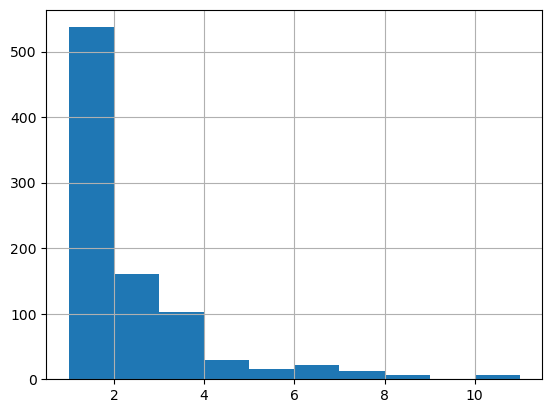

In [164]:
titanic_ds["family_size"].hist()

In [165]:
titanic_ds["family_size"].skew()

np.float64(2.7274414739308535)

Yikes! In this case, i'd probably use a poisson or negative-binomial count model. I highly expect our residuals to be skewed, but let's due diligencne.

<Axes: >

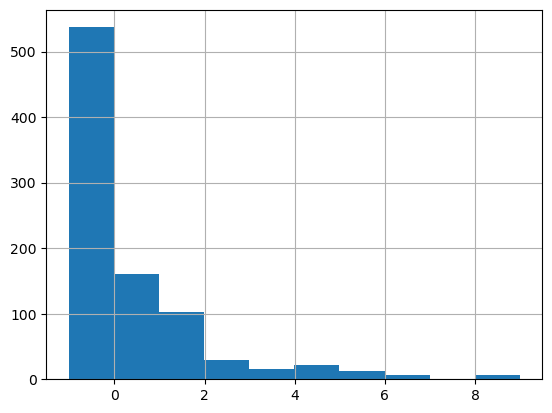

In [166]:
mod.resid.hist()

Yes, that is comically bad. Let's engineer a new feature that better fits model assumptions.

In [167]:
titanic_ds["family_size_sqrt"] = np.sqrt(titanic_ds["family_size"])

In [168]:
mod_sqrt = smf.ols(
    formula = "family_size_sqrt ~ C(ship_class)",
    data=titanic_ds
).fit()

print(mod_sqrt.summary())

                            OLS Regression Results                            
Dep. Variable:       family_size_sqrt   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.001
Method:                 Least Squares   F-statistic:                    0.3686
Date:                Tue, 20 Oct 2026   Prob (F-statistic):              0.692
Time:                        13:50:21   Log-Likelihood:                -575.72
No. Observations:                 891   AIC:                             1157.
Df Residuals:                     888   BIC:                             1172.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

Shockingly even less evidence now. 

Does the resid issue get better?

<Axes: >

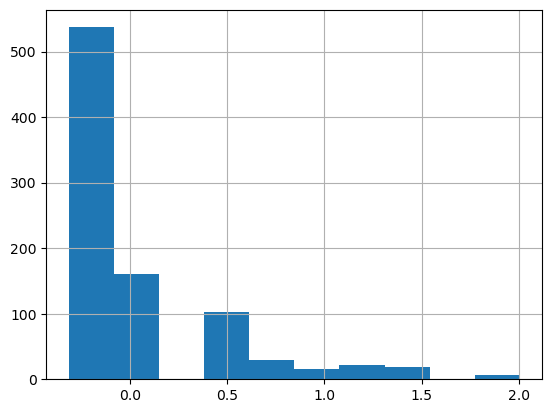

In [169]:
mod_sqrt.resid.hist()

Not really

In [170]:
# does sex predict a higher family size? I assume so and assume it interacts with being in steerage

titanic_ds["is_steerage"] = titanic_ds["ship_class"] == "Third"
titanic_ds["is_male"] = titanic_ds["sex"] == "male"

mod_int = smf.ols(
    formula = "family_size_sqrt ~ is_steerage * is_male",
    data=titanic_ds
).fit()

print(mod_int.summary())


                            OLS Regression Results                            
Dep. Variable:       family_size_sqrt   R-squared:                       0.066
Model:                            OLS   Adj. R-squared:                  0.062
Method:                 Least Squares   F-statistic:                     20.76
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           5.28e-13
Time:                        13:50:21   Log-Likelihood:                -545.86
No. Observations:                 891   AIC:                             1100.
Df Residuals:                     887   BIC:                             1119.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

## Logit

In [171]:
mod_surv = smf.logit(
    formula = "survived ~ is_male * C(ship_class)",
    data = titanic_ds
).fit()

print(mod_surv.summary())

Optimization terminated successfully.
         Current function value: 0.447866
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:               survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      885
Method:                           MLE   Df Model:                            5
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.3274
Time:                        13:50:21   Log-Likelihood:                -399.05
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 8.670e-82
                                              coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------
Intercept                                 1.58e-16

Controlling for class, I would assume that traveling alone as a woman increased your odds of survival


In [172]:
titanic_ds = (
    titanic_ds
    .assign(
        travel_alone = lambda d: (d["parch"] == 0) & (d["sibsp"] == 0)
    )
)

In [173]:
mod_3way = smf.logit(
    formula = "survived ~ travel_alone * is_steerage * is_male",
    data=titanic_ds
).fit()

print(mod_3way.summary())

Optimization terminated successfully.
         Current function value: 0.449136
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:               survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      883
Method:                           MLE   Df Model:                            7
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.3255
Time:                        13:50:21   Log-Likelihood:                -400.18
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 2.071e-79
                                                               coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------------------
Intercept       

In [174]:
print(
    smf.logit(
        formula = "survived ~ travel_alone  + is_steerage * is_male",
        data=titanic_ds
    )
    .fit()
    .summary()
)

Optimization terminated successfully.
         Current function value: 0.455979
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:               survived   No. Observations:                  891
Model:                          Logit   Df Residuals:                      886
Method:                           MLE   Df Model:                            4
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.3153
Time:                        13:50:21   Log-Likelihood:                -406.28
converged:                       True   LL-Null:                       -593.33
Covariance Type:            nonrobust   LLR p-value:                 1.095e-79
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                               2.9528      0.351 

Huh

# Regression Deep Dive with Difference in Differences

This is a dataset for longitudinal data for 6 employeees
- 3 untreated @ 5 timetpoints
- 3 treated @ 5 timepoints

In [175]:
df = pd.DataFrame({
    "employee": ["A"]*6 + ["B"]*6 + ["C"]*6 + ["D"]*6 + ["E"]*6 + ["F"]*6,
    "treated":  [0]*18 + [1]*18,
    "time":     [1, 2, 3, 4, 5, 6]*6,
    "score": [
        50, 51, 52, 53, 54, 55,  # A: control
        60, 61, 62, 63, 64, 65,  # B: control
        70, 71, 72, 73, 74, 75,  # C: control
        55, 56, 57, 61, 65, 69,  # D: treated
        65, 66, 67, 71, 75, 79,  # E: treated
        75, 76, 77, 81, 85, 89   # F: treated
    ]
})

df["post"] = (df["time"] >= 4).astype(int)


Let's do a plot

In [176]:
import plotnine as p9

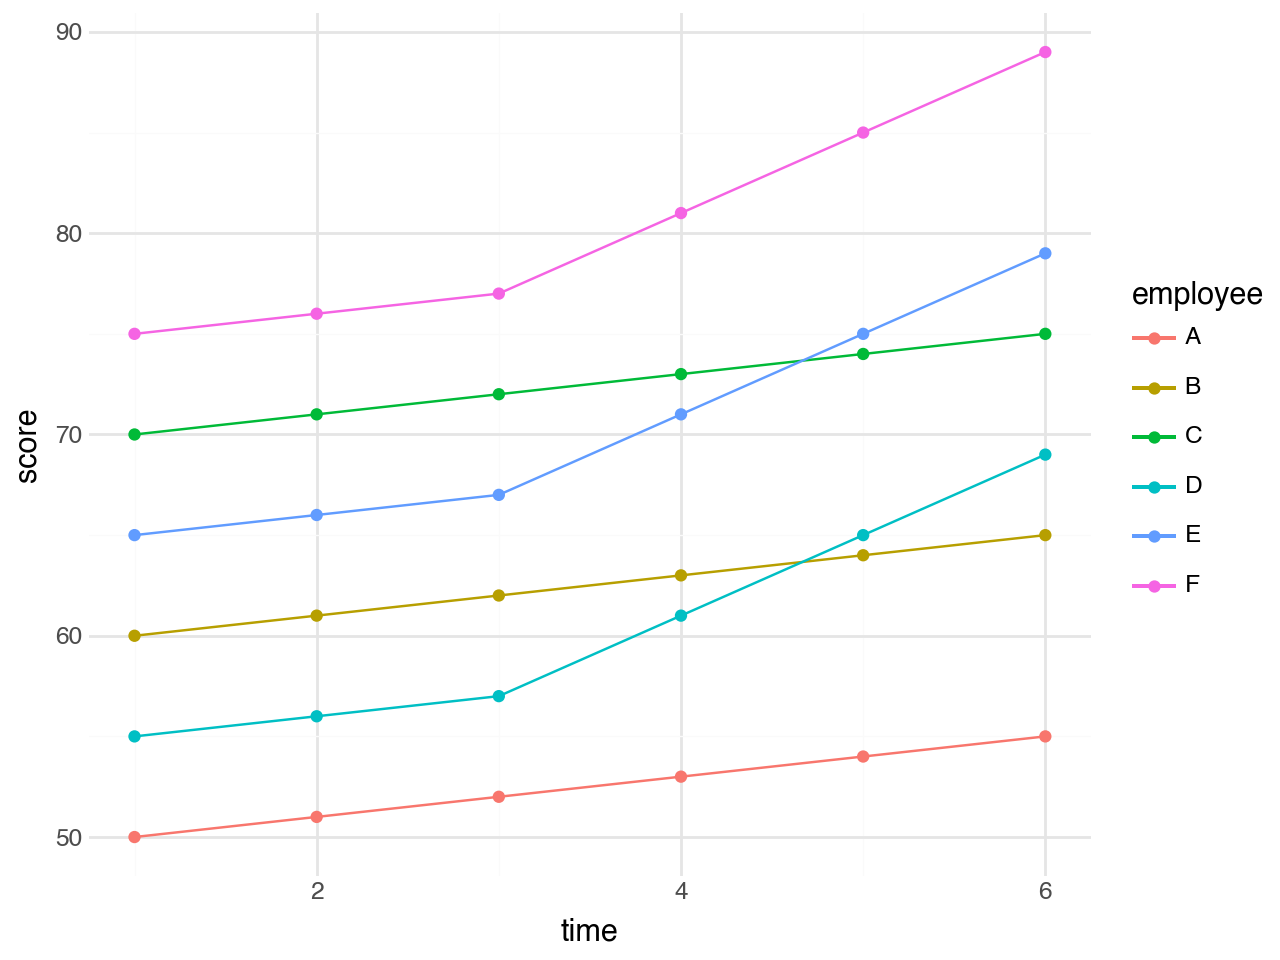

In [177]:
(
    p9.ggplot(
        data = df,
        mapping = p9.aes(x="time", y="score", color="employee")
    )
    + p9.geom_line()
    + p9.geom_point()
    + p9.theme_minimal()
)

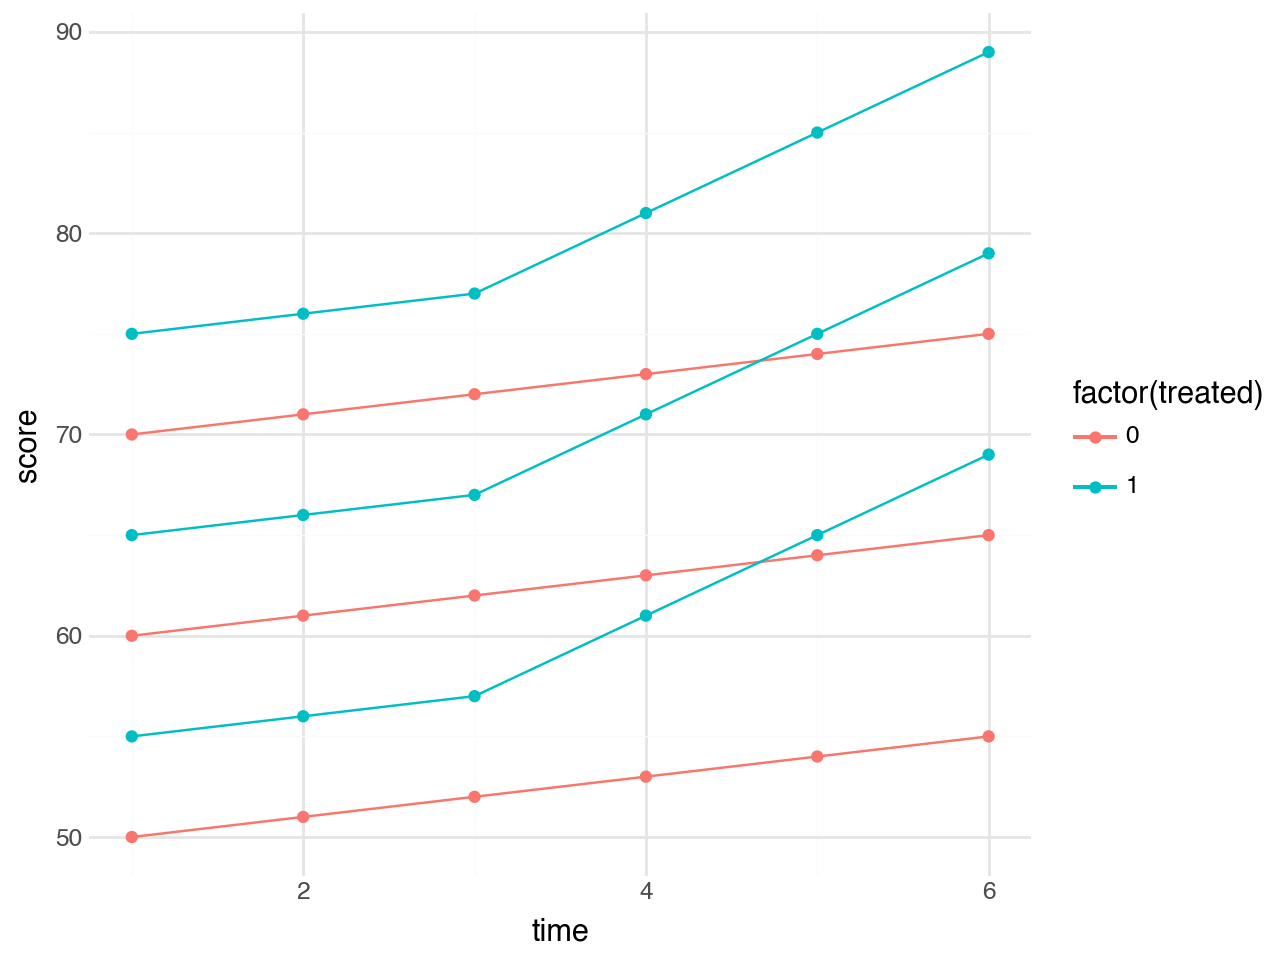

In [178]:
(
    p9.ggplot(
        data = df, 
        mapping=p9.aes(x="time", y="score", color="factor(treated)")
        )
    + p9.geom_line(mapping=p9.aes(group = "employee"))
    + p9.geom_point()
    + p9.theme_minimal()
)

Let's walk through how we'd use regression here.

- We put employee as a categorical predictor. That way, the main intercept is employee 0, and we get an interdept for each employee as well. In econometrics, this is fixed effects.
- We need a cluster standard error. This allows autocorrelation of residuals within persons (clusters), allows different residuals across clusters (e.g., one person can haver more or less residual than another, but requires that clusters be indedependnt. 

In [179]:
model = smf.ols(
    formula="score ~ time + C(employee)",
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["employee"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       0.965
Model:                            OLS   Adj. R-squared:                  0.958
Method:                 Least Squares   F-statistic:                     17.59
Date:                Tue, 20 Oct 2026   Prob (F-statistic):            0.00854
Time:                        13:50:21   Log-Likelihood:                -73.148
No. Observations:                  36   AIC:                             160.3
Df Residuals:                      29   BIC:                             171.4
Df Model:                           6                                         
Covariance Type:              cluster                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           45.7000      1.621  

/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 6, but rank is 1


This equation models

- $i$ = employee
- $t$ = time

$y = \alpha_i + \beta \times time_{t} + \epsilon_{it}$

The $\alpha$ parameters are the intercept and betas for employees, and the single effect of time is the $\beta$ for time


Next, let's look at before the intervention. 

In [180]:
pre = df.copy()

pre = pre.loc[pre["post"] == 0]

pre

,employee,treated,time,score,post
0,A,0,1,50,0
1,A,0,2,51,0
2,A,0,3,52,0
6,B,0,1,60,0
7,B,0,2,61,0
8,B,0,3,62,0
12,C,0,1,70,0
13,C,0,2,71,0
14,C,0,3,72,0
18,D,1,1,55,0


We will now check for parallel trends. This ensures we have people on roughly the same trajectory BEFORE the intervention.

This is nicely comparable to a 2 (treated) x 3 (time) anova


In [181]:
model = smf.ols(
    data = pre,
    formula = "score ~ C(employee) + C(time) + C(time):treated"
).fit(
    cov_type="cluster",
    cov_kwds={"groups": pre["employee"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 1.021e+30
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           4.74e-75
Time:                        13:50:21   Log-Likelihood:                 553.45
No. Observations:                  18   AIC:                            -1087.
Df Residuals:                       8   BIC:                            -1078.
Df Model:                           9                                         
Covariance Type:              cluster                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             50.0000    6.6

/var/folders/bj/45wmvwcj3njb1xt57ps1k86r0000gn/T/ipykernel_45324/1067659717.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 10, but rank is 6
/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:2121: RuntimeWarning: invalid value encountered in sqrt


> You will see that we have multicollinearity here. 

> The reason is that 
- Each `time x treatment` interaction is `1` for an observation that is both treated at that time, `0` otherwise
- As a result, the sum of those `time x treatment` interactions turns into `treatment`. 
- `treated` is not in the model on purpose, as it is redundant to the `employee` variable (since employees are nested within treatments)
- Therefore, we cannot have all 3 `time x treated` terms. The fix is to drop one, as is commonly done in ANOVA models where you have a reference category. Here, the interaction term omitted becomes the reference category
- Consequently, the intercept becomes "what is true when all categorical variables and interactions are in their reference value" 

In [186]:
pre = (
    pre
    .assign(
        time2_treated = lambda d: ((d["time"] == 2) & (d["treated"] == 1)).astype("int"),
        time3_treated = lambda d: ((d["time"] == 3) & (d["treated"] == 1)).astype("int")
    )
)


> Now we can run the model again

In [185]:
# int terms already dummy coded

model = smf.ols(
    data = pre,
    formula = "score ~ C(employee) + C(time) + time2_treated + time3_treated"
).fit(
    cov_type = "cluster", 
    cov_kwds = {"groups": pre["employee"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  score   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 3.550e+29
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           6.65e-74
Time:                        13:50:41   Log-Likelihood:                 536.86
No. Observations:                  18   AIC:                            -1054.
Df Residuals:                       8   BIC:                            -1045.
Df Model:                           9                                         
Covariance Type:              cluster                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           50.0000   8.17e-15  

/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 9, but rank is 6


> Notice that neither time-treament interaction component is significant. The interaction has been fully decomposed into those two components.

> We can test them in omnibus with `model.wald_test()`, which is equivalent to the ombnibus F for the itneraction we'd get in an ANOVA

In [188]:
model.wald_test("time2_treated = 0, time3_treated = 0")

<class 'statsmodels.stats.contrast.ContrastResults'>
<Wald test (chi2): statistic=1.867504283266514, p-value=0.3930760628733047, df_denom=2>

We could do similar things for time and for employee

In [ ]:
#omnibus time test
model.wald_test("C(time)[T.2] = 0, C(time)[T.3] = 0")

<class 'statsmodels.stats.contrast.ContrastResults'>
<Wald test (chi2): statistic=1.059200033613248e+27, p-value=0.0, df_denom=2>

> Note that the wald chi-square tests are a direct transform of the F-value we'd get in a mixed ANOVA. However, the p-values may or may not be becuase we have estimated the variance with special kinds of variance modifications. In ANOVA, we handle that by using sphericity assumptions and have backup corrections. 

This equation models:

$score_{it} = \alpha_{i} + \lambda_{t} + \beta_{1} ( time_{t} \times treated_{i}) + \epsilon_{it}$

Let's unpack where:
- alphas are the intercepts (main effect of people)
- lambdas (new!) are the time points (main effect of time)
- effect of treatment *is baked into the intercepts* so we cannot model it separately!
- effect of treatment on time ... that's $beta_1$

In [191]:
#for fun, let's unpack coefficients

pd.DataFrame({
    "estimate": model.params,
    "se": model.bse,
    "p": model.pvalues,
    "ci_low": model.conf_int()[0],
    "ci_high": model.conf_int()[1]
}).round(3)

,estimate,se,p,ci_low,ci_high
Intercept,50.0,0.0,0.000,50.0,50.0
C(employee)[T.B],10.0,0.0,0.000,10.0,10.0
C(employee)[T.C],20.0,0.0,0.000,20.0,20.0
C(employee)[T.D],5.0,0.0,0.000,5.0,5.0
C(employee)[T.E],15.0,0.0,0.000,15.0,15.0
C(employee)[T.F],25.0,0.0,0.000,25.0,25.0
C(time)[T.2],1.0,0.0,0.000,1.0,1.0
C(time)[T.3],2.0,0.0,0.000,2.0,2.0
time2_treated,0.0,0.0,0.871,-0.0,0.0
time3_treated,-0.0,0.0,0.278,-0.0,0.0


Notice confidence intevrals are tightly around zero. 

In [ ]:
#explroe more
model.conf_int()

,0,1
Intercept,5.000000e+01,5.000000e+01
C(employee)[T.B],1.000000e+01,1.000000e+01
C(employee)[T.C],2.000000e+01,2.000000e+01
C(employee)[T.D],5.000000e+00,5.000000e+00
C(employee)[T.E],1.500000e+01,1.500000e+01
C(employee)[T.F],2.500000e+01,2.500000e+01
C(time)[T.2],1.000000e+00,1.000000e+00
C(time)[T.3],2.000000e+00,2.000000e+00
time2_treated,-7.870489e-14,9.291575e-14
time3_treated,-1.196695e-13,3.440437e-14


In [ ]:
# explore more

> Of course, we could make time a continuous predictor if we had that precision

> We can also grab all of the printout from the ols summary with `model.summary2()` and each table with `model.summary2().tables[2]`

In [202]:
model.summary2().tables[1]

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
Intercept,5.000000e+01,8.170383e-15,6.119664e+15,0.000000,5.000000e+01,5.000000e+01
C(employee)[T.B],1.000000e+01,2.753449e-14,3.631809e+14,0.000000,1.000000e+01,1.000000e+01
C(employee)[T.C],2.000000e+01,3.118843e-14,6.412635e+14,0.000000,2.000000e+01,2.000000e+01
C(employee)[T.D],5.000000e+00,8.914619e-15,5.608765e+14,0.000000,5.000000e+00,5.000000e+00
C(employee)[T.E],1.500000e+01,9.926900e-15,1.511046e+15,0.000000,1.500000e+01,1.500000e+01
C(employee)[T.F],2.500000e+01,9.926900e-15,2.518410e+15,0.000000,2.500000e+01,2.500000e+01
C(time)[T.2],1.000000e+00,3.072635e-14,3.254535e+13,0.000000,1.000000e+00,1.000000e+00
C(time)[T.3],2.000000e+00,8.731016e-22,2.290684e+21,0.000000,2.000000e+00,2.000000e+00
time2_treated,7.105427e-15,4.378158e-14,1.622926e-01,0.871075,-7.870489e-14,9.291575e-14
time3_treated,-4.263256e-14,3.930528e-14,-1.084652e+00,0.278076,-1.196695e-13,3.440437e-14


In a real DiD context:
- Nonsig int? Great! But check CI + Plot
- Large nonsig effect? Check CI + power. May not have enough data to say much.
- Small sig effect? Assess if it's relevant
- Big sig interaction - may need another design

A small sig difference is common. So how would I know if it's impactful if nonsig?

I'd look at how much of the treatment effect it might eat up? 2 point gain over 6 months is treatment effect? how much of that could be accounted for simply by non-parallel trends?

## Now it's time for DiD



We will estimate something similar

$score_{it} = alpha_{i} + \lambda_{t} + \beta_1{} (post_{t} \times treated_{it})$

A few notes: 
- As before, `treated` indicates whether you are in the treatment group. It encompasses the intercepts so we do NOT have a main effect of `treated` in this model
- The interaction is now with `post` ... the goal is to know whether the `treated` contrast differs pre/post intervention
- the `treated` x `post` interaction is the 2-way ANOVA concept and it is now a 2x2, so no need to specifiy interaction components

In [207]:
model = smf.ols(
    data = df, 
    formula = "score ~ C(employee) + C(time) + treated:post"
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["employee"]}
)

model.summary()

/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 11, but rank is 1
/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/regression/linear_model.py:2121: RuntimeWarning: invalid value encountered in sqrt


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  score   R-squared:                       0.992
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                     9.524
Date:                Tue, 20 Oct 2026   Prob (F-statistic):             0.0273
Time:                        14:14:19   Log-Likelihood:                -45.904
No. Observations:                  36   AIC:                             115.8
Df Residuals:                      24   BIC:                             134.8
Df Model:                          11                                         
Covariance Type:              cluster                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           50.0000   1.31e-08    3.8e+09      0.000      50.000      50.000
C(employee)[T.B]    10.0000   1.03e-13   9.68e+13      0.000      10.000      10.000
C(employee)[T.C]    20.0000   5.43e-14   3.68e+14      0.000      20.000      20.000
C(employee)[T.D]     5.0000        nan        nan        nan         nan         nan
C(employee)[T.E]    15.0000   6.85e-14   2.19e+14      0.000      15.000      15.000
C(employee)[T.F]    25.0000        nan        nan        nan         nan         nan
C(time)[T.2]         1.0000        nan        nan        nan         nan         nan
C(time)[T.3]         2.0000        nan        nan        nan         nan         nan
C(time)[T.4]         1.5000      0.810      1.852      0.064      -0.088       3.088
C(time)[T.5]         4.0000        nan        nan        nan         nan         nan
C(time)[T.6]         6.5000      0.810      8.024      0.000       4.912       8.088
treated:post         6.0000   1.31e-08   4.57e+08      0.000       6.000       6.000
==============================================================================
Omnibus:                        0.229   Durbin-Watson:                   1.917
Prob(Omnibus):                  0.892   Jarque-Bera (JB):                0.000
Skew:                          -0.000   Prob(JB):                         1.00
Kurtosis:                       3.000   Cond. No.                         9.77
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (CRV1)
"""

The effect size here is `treated:post` meaning that the difference between the two groups is 6 points larger post-treatment than it was pre-treeatement.

### Conduct robustness and sensitivity analyses

Event-study model - Does the treatment effect evolve over time?

For this one, we want to look at the difference between (treated and untreated) `treated` for each pairwise timepoints. In other words, how much has the difference changed goign from time_2 to time_3? This can be descriptive but is still useful.

In [224]:
(
    pd.pivot_table(
        index = "time", 
        columns = "treated", 
        values = "score",
        data = df,
        aggfunc="mean"
    )
    .reset_index()
    .assign(
        diff = lambda d: d[0] - d[1],
        prior_diff = lambda d: d["diff"].shift(1),
        diff_in_diff_adjacent = lambda d: d["diff"] - d["prior_diff"],
        diff_in_diff_vs_ref = lambda d: d["diff"] - d.loc[d["time"]==3, "diff"].iloc[0]
    )
    
)

treated,time,0,1,diff,prior_diff,diff_in_diff_adjacent,diff_in_diff_vs_ref
0,1,60.0,65.0,-5.0,NaN,NaN,0.0
1,2,61.0,66.0,-5.0,-5.0,0.0,0.0
2,3,62.0,67.0,-5.0,-5.0,0.0,0.0
3,4,63.0,71.0,-8.0,-5.0,-3.0,-3.0
4,5,64.0,75.0,-11.0,-8.0,-3.0,-6.0
5,6,65.0,79.0,-14.0,-11.0,-3.0,-9.0


> Normally, this is done via regression where you can also do covariate adjustment

In [231]:
df = (
    df
    .assign(
        time1_treated = lambda d: ((d["time"] == 1) & (d["treated"] == 1)).astype("int"),
        time2_treated = lambda d: ((d["time"] == 2) & (d["treated"] == 1)).astype("int"),
        # OMIT TIME 3 -- that is reference
        time4_treated = lambda d: ((d["time"] == 4) & (d["treated"] == 1)).astype("int"),
        time5_treated = lambda d: ((d["time"] == 5) & (d["treated"] == 1)).astype("int"),
        time6_treated = lambda d: ((d["time"] == 6) & (d["treated"] == 1)).astype("int")
    )
)

model = smf.ols(
    data = df,
    formula = "score ~ C(employee) + C(time) + time1_treated + time2_treated + time4_treated + time5_treated + time6_treated"
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["employee"]}
)

model.summary()

/Users/thomascarpenter/anaconda3/envs/dsbase/lib/python3.13/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 15, but rank is 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  score   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                -1.976e+41
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               1.00
Time:                        16:58:14   Log-Likelihood:                 1068.8
No. Observations:                  36   AIC:                            -2106.
Df Residuals:                      20   BIC:                            -2080.
Df Model:                          15                                         
Covariance Type:              cluster                                         
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           50.0000   2.98e-14   1.68e+15      0.000      50.000      50.000
C(employee)[T.B]    10.0000   3.57e-14    2.8e+14      0.000      10.000      10.000
C(employee)[T.C]    20.0000   3.38e-14   5.91e+14      0.000      20.000      20.000
C(employee)[T.D]     5.0000   5.23e-14   9.55e+13      0.000       5.000       5.000
C(employee)[T.E]    15.0000   4.07e-14   3.68e+14      0.000      15.000      15.000
C(employee)[T.F]    25.0000   2.68e-14   9.34e+14      0.000      25.000      25.000
C(time)[T.2]         1.0000   2.79e-14   3.59e+13      0.000       1.000       1.000
C(time)[T.3]         2.0000   2.38e-14   8.41e+13      0.000       2.000       2.000
C(time)[T.4]         3.0000   3.97e-14   7.55e+13      0.000       3.000       3.000
C(time)[T.5]         4.0000   5.94e-14   6.73e+13      0.000       4.000       4.000
C(time)[T.6]         5.0000   5.75e-14   8.69e+13      0.000       5.000       5.000
time1_treated     3.197e-14    2.4e-14      1.331      0.183   -1.51e-14    7.91e-14
time2_treated    -3.197e-14   2.25e-14     -1.421      0.155   -7.61e-14    1.21e-14
time4_treated        3.0000   4.84e-14    6.2e+13      0.000       3.000       3.000
time5_treated        6.0000   3.84e-14   1.56e+14      0.000       6.000       6.000
time6_treated        9.0000   3.53e-14   2.55e+14      0.000       9.000       9.000
==============================================================================
Omnibus:                        2.260   Durbin-Watson:                   1.371
Prob(Omnibus):                  0.323   Jarque-Bera (JB):                2.085
Skew:                           0.545   Prob(JB):                        0.353
Kurtosis:                       2.552   Cond. No.                         17.0
==============================================================================

Notes:
[1] Standard Errors are robust to cluster correlation (CRV1)
"""

Other considerations

- Alternative comparison groups - Does the result depend on which employees serve as controls? This is a design question
- Placebo intervetion date - Look at the event-study version and see if the evidence for the effect emerges early

> In that one, however, there is a standard analysis where you pretend the event occured early (recode it) and run the analysis again on only the pre-treatement data. Woudl our design "detect" an effect that's not there?

- Sensitivty to pre-trend violations. Already discussed this above. 
- Covariate adjustment - are there things we shoudl control for?
- Heterogenous treatment effects - look for interactions with binary subgroup flags (any evidence that subgroups differ?). Moderation


# Multilevel Models

# Stats Tests

# Instrumental Variable

# Propensity Matching